The error (noise) added to the simulated clonal data is additive Gaussian (normal) noise.

### How the Noise is Calculated

For each cell type $j$ at each timepoint, the standard deviation ($\text{dev}$) is calculated first. This represents a standard deviation of 20% relative to the deterministic model’s population size:
$$ \text{dev} = \text{model\_deterministic} \times 0.2 $$

Next, a zero-compartment baseline is applied. To allow stochastic fluctuations in empty cell states, a baseline standard deviation is set where the deterministic count is zero:
$$ \text{dev}[\text{dev} == 0] = 1 $$

Finally, standard normal noise is generated and rounded. It is scaled by $\text{dev}$, added to the deterministic values, rounded to the nearest integer, and lower-bounded at $0$ to prevent negative cell counts:
$$ \text{noisy\_counts} = \max\left(0, \text{round}\left(\text{model\_deterministic} + \mathcal{N}(0, 1) \times \text{dev}\right)\right) $$

### Consistency Across Metaclones

The noise logic is identical across all 12 metaclones, with two specific exceptions.

In Meta9 (catastrophic collapse or cell dying out), the clone collapses to absolute zero at day 15. To prevent the noise logic from stochastically re-generating cells after extinction, the baseline deviation for zero cell counts is set to a tiny epsilon instead of 1:
$$ \text{dev}[\text{dev} == 0] = 0.01 $$

Additionally, each metaclone utilizes a different random stochastic seed for parameter and noise generation. For example, Meta3 uses seed 300 and Meta4 uses seed 400, meaning the random noise realizations will differ between metaclones.

# 1. Baseline Haematopoiesis (Meta1)

**Metaclone Type**: Standard baseline deterministic hematopoiesis.
- **Initial Conditions**: HSC = 1.0, all other compartments start at 0.
- **Target Sums**: Rescaled to standard population sizes of `[10, 100, 300, 400]` at timepoints `[0, 2, 7.5, 15]`.
- **Parameters**: Baseline parameters representing standard hematopoiesis rates.
- **Replicates**: 15 noise replicates.


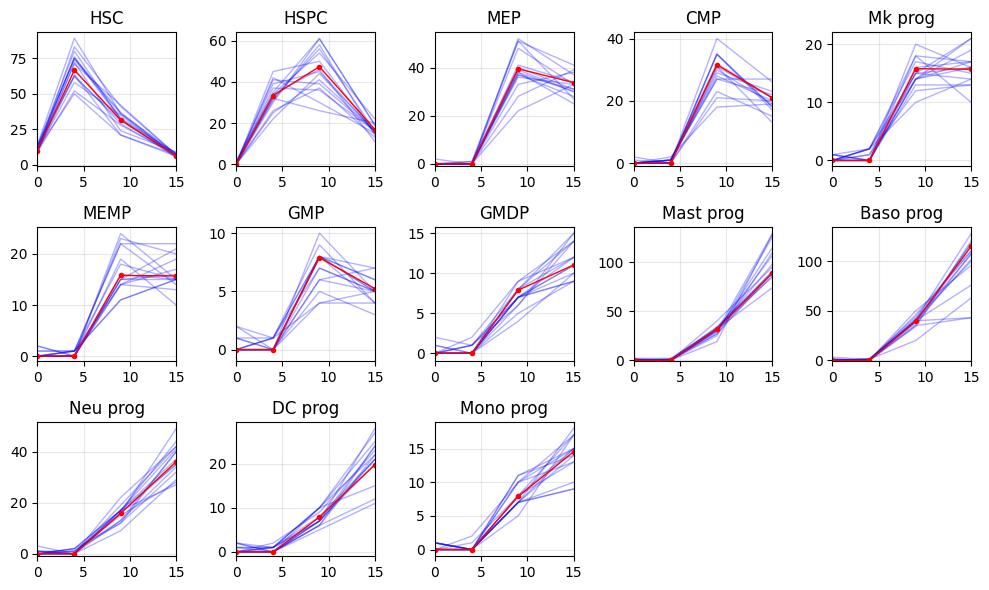

Simulation complete. Data saved to: in_silico/simulated_data/simulated_clones_meta1.csv
Data shape: (15, 52) (15 replicates x 52 features)


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import os

# ---------------------------------------------------------
# 1. Define Parameters and ODE System
# ---------------------------------------------------------

def hematopoietic_model(t, y):
    dydt = np.zeros_like(y)
    
    # Parameters
    p_hsc, d_hsc, m_hsc = 0.3, 0.13, 0.01
    p_hspc, d_hspc, m_hspc = 0.35, 0.14, 0.01
    p_mep, d_mep, m_mep = 0.4, 0.1, 0.01
    p_cmp, d_cmp, m_cmp = 0.31, 0.09, 0.01
    p_mk, m_mk = 0.22, 0.01
    p_memp, d_memp, m_memp = 0.7, 0.6, 0.05
    p_gmp, d_gmp, m_gmp = 0.9, 0.8, 0.08
    p_gmdp, d_gmdp, m_gmdp = 0.6, 0.3, 0.07
    p_mast, m_mast = 0.51, 0.09
    p_baso, m_baso = 0.5, 0.03
    p_neu, m_neu = 0.4, 0.033
    p_dc, m_dc = 0.44, 0.1
    p_mono, m_mono = 0.45, 0.2

    x = y 

    # ODE Equations
    dydt[0] = (p_hsc - d_hsc - m_hsc) * x[0] 
    dydt[1] = (p_hspc - d_hspc - m_hspc) * x[1] + d_hsc * x[0]
    dydt[2] = (p_mep - d_mep - m_mep) * x[2] + d_hspc * x[1]
    dydt[3] = (p_cmp - d_cmp - m_cmp) * x[3] + d_hspc * x[1]
    dydt[4] = (p_mk - m_mk) * x[4] + d_mep * x[2]
    dydt[5] = (p_memp - d_memp - m_memp) * x[5] + d_mep * x[2] + d_cmp * x[3]
    dydt[6] = (p_gmp - d_gmp - m_gmp) * x[6] + d_cmp * x[3]
    dydt[7] = (p_gmdp - d_gmdp - m_gmdp) * x[7] + d_cmp * x[3]
    dydt[8] = (p_mast - m_mast) * x[8] + d_memp * x[5]
    dydt[9] = (p_baso - m_baso) * x[9] + d_memp * x[5]
    dydt[10] = (p_neu - m_neu) * x[10] + d_gmp * x[6]
    dydt[11] = (p_dc - m_dc) * x[11] + d_gmdp * x[7]
    dydt[12] = (p_mono - m_mono) * x[12] + d_gmdp * x[7]

    return dydt

# ---------------------------------------------------------
# 2. Simulation Setup
# ---------------------------------------------------------

cell_types = ['HSC', 'HSPC', 'MEP', 'CMP', 'Mk prog', 'MEMP', 
              'GMP', 'GMDP', 'Mast prog', 'Baso prog', 'Neu prog', 
              'DC prog', 'Mono prog']

time_points = np.array([0, 4, 9, 15])
# FIX: Use linspace instead of arange to avoid floating point issues
t_plot = np.linspace(0, 20, 2001)  # 2001 points gives 0.01 spacing
I0 = np.zeros(13)
I0[0] = 1.0

# ---------------------------------------------------------
# 3. Solve ODEs (Deterministic)
# ---------------------------------------------------------

sol_plot = solve_ivp(hematopoietic_model, [0, 20], I0, t_eval=t_plot, method='RK45')
sol_sample = solve_ivp(hematopoietic_model, [0, 15], I0, t_eval=time_points, method='RK45')

# Determine model values at sampling points (Time x Cell)
model_deterministic = np.round(sol_sample.y.T)

# --- SCALING SECTION ---
# Calculate current sum across cells for each timepoint
current_sums = model_deterministic.sum(axis=1, keepdims=True)

# Target sums for each timepoint: [10, 100, 300, 400]
target_sums = np.array([10, 100, 300, 400]).reshape(-1, 1)

# Normalize and Scale: (Model / Current_Sum) * Target_Sum
model_deterministic = (model_deterministic / current_sums) * target_sums
# ----------------------

# Calculate deviation
dev = model_deterministic * 0.2
dev[dev == 0] = 1 

# ---------------------------------------------------------
# 4. Generate Noise Replicates
# ---------------------------------------------------------

num_replicates = 15
model_noise_store = np.zeros((num_replicates, len(time_points) * 13))
all_noisy_trajectories = [] 

for nn in range(1, num_replicates + 1):
    np.random.seed(nn)
    
    noise = np.random.randn(*model_deterministic.shape) * dev
    model_noise = model_deterministic + noise
    
    model_noise = np.round(model_noise)
    model_noise[model_noise < 0] = 0
    
    # Store flattened (row-major)
    model_noise_store[nn-1, :] = model_noise.flatten() 
    all_noisy_trajectories.append(model_noise)

# ---------------------------------------------------------
# 5. Plotting
# ---------------------------------------------------------

fig, axes = plt.subplots(3, 5, figsize=(10, 6))
axes = axes.flatten()

for j in range(13):
    ax = axes[j]
    
    # Plot noisy replicates (the actual saved data)
    for noisy_data in all_noisy_trajectories:
        ax.plot(time_points, noisy_data[:, j], '-b', alpha=0.3, linewidth=1)
    
    # Plot mean of scaled deterministic model at sample points
    ax.plot(time_points, model_deterministic[:, j], '-ro', linewidth=1, 
            markersize=3, label='Scaled model' if j==0 else "")

    ax.set_title(cell_types[j])
    ax.set_ylim(bottom=-1)
    ax.set_xlim([0, 15])  # Match data range
    ax.grid(True, alpha=0.3)

axes[13].axis('off')
axes[14].axis('off')

if axes[0].get_legend():
    axes[0].legend()

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 6. Saving Data
# ---------------------------------------------------------

output_folder = "in_silico/simulated_data/"
filename = "simulated_clones_meta1.csv"
file_path = os.path.join(output_folder, filename)

if not os.path.exists(output_folder):
    os.makedirs(output_folder)

# COMMENT: Saving the scaled simulated noise data to CSV
np.savetxt(file_path, model_noise_store, delimiter=",", fmt='%.4f')

print(f"Simulation complete. Data saved to: {file_path}")
print(f"Data shape: {model_noise_store.shape} (15 replicates x {len(time_points)*13} features)")

# 2. Altered Initial Conditions & Baseline Parameters (Meta2)

**Metaclone Type**: Baseline parameters with customized initial cell distribution.
- **Initial Conditions**: HSC = 2.0, HSPC = 1.0, all other compartments start at 0.
- **Target Sums**: Rescaled to standard population sizes of `[10, 100, 300, 400]`.
- **Parameters**: Deterministic rates slightly modified from Meta1 (`p_hsc = 0.2`, `d_hsc = 0.1`, `m_hsc = 0.02` etc.).
- **Replicates**: 30 noise replicates.


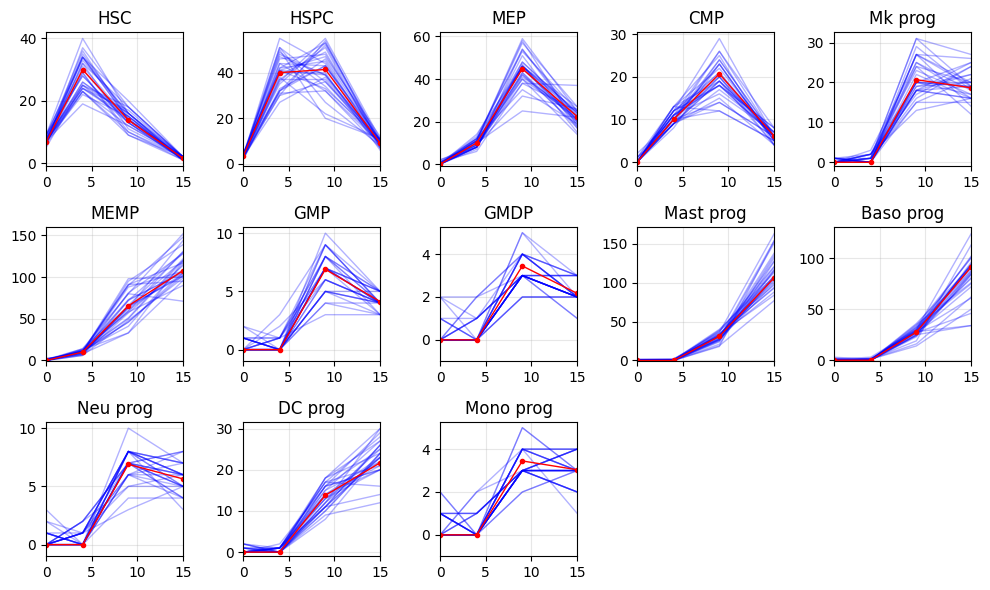

META2 Simulation complete. Data saved to: in_silico/simulated_data/simulated_clones_meta2.csv
Data shape: (30, 52) (30 replicates x 52 features)


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import os

# ---------------------------------------------------------
# 1. Define Parameters and ODE System - META2
# ---------------------------------------------------------

def hematopoietic_model_meta2(t, y):
    dydt = np.zeros_like(y)
    
    # META2 Parameters
    p_hsc, d_hsc, m_hsc = 0.2, 0.1, 0.02
    p_hspc, d_hspc, m_hspc = 0.3, 0.1, 0.011
    p_mep, d_mep, m_mep = 0.41, 0.11, 0.012
    p_cmp, d_cmp, m_cmp = 0.2, 0.09, 0.02
    p_mk, m_mk = 0.29, 0.02
    p_memp, d_memp, m_memp = 0.6, 0.1, 0.015
    p_gmp, d_gmp, m_gmp = 0.5, 0.3, 0.018
    p_gmdp, d_gmdp, m_gmdp = 0.4, 0.3, 0.071
    p_mast, m_mast = 0.6, 0.08
    p_baso, m_baso = 0.51, 0.02
    p_neu, m_neu = 0.3, 0.133
    p_dc, m_dc = 0.6, 0.11
    p_mono, m_mono = 0.145, 0.012

    x = y 

    # ODE Equations
    dydt[0] = (p_hsc - d_hsc - m_hsc) * x[0] 
    dydt[1] = (p_hspc - d_hspc - m_hspc) * x[1] + d_hsc * x[0]
    dydt[2] = (p_mep - d_mep - m_mep) * x[2] + d_hspc * x[1]
    dydt[3] = (p_cmp - d_cmp - m_cmp) * x[3] + d_hspc * x[1]
    dydt[4] = (p_mk - m_mk) * x[4] + d_mep * x[2]
    dydt[5] = (p_memp - d_memp - m_memp) * x[5] + d_mep * x[2] + d_cmp * x[3]
    dydt[6] = (p_gmp - d_gmp - m_gmp) * x[6] + d_cmp * x[3]
    dydt[7] = (p_gmdp - d_gmdp - m_gmdp) * x[7] + d_cmp * x[3]
    dydt[8] = (p_mast - m_mast) * x[8] + d_memp * x[5]
    dydt[9] = (p_baso - m_baso) * x[9] + d_memp * x[5]
    dydt[10] = (p_neu - m_neu) * x[10] + d_gmp * x[6]
    dydt[11] = (p_dc - m_dc) * x[11] + d_gmdp * x[7]
    dydt[12] = (p_mono - m_mono) * x[12] + d_gmdp * x[7]

    return dydt

# ---------------------------------------------------------
# 2. Simulation Setup
# ---------------------------------------------------------

cell_types = ['HSC', 'HSPC', 'MEP', 'CMP', 'Mk prog', 'MEMP', 
              'GMP', 'GMDP', 'Mast prog', 'Baso prog', 'Neu prog', 
              'DC prog', 'Mono prog']

time_points = np.array([0, 4, 9, 15])
t_plot = np.linspace(0, 20, 2001)

# META2 Initial Conditions: HSC=2, HSPC=1, others=0
I0 = np.zeros(13)
I0[0] = 2.0  # HSC
I0[1] = 1.0  # HSPC

# ---------------------------------------------------------
# 3. Solve ODEs (Deterministic)
# ---------------------------------------------------------

sol_plot = solve_ivp(hematopoietic_model_meta2, [0, 20], I0, t_eval=t_plot, method='RK45')
sol_sample = solve_ivp(hematopoietic_model_meta2, [0, 15], I0, t_eval=time_points, method='RK45')

# Determine model values at sampling points (Time x Cell)
model_deterministic = np.round(sol_sample.y.T)

# --- SCALING SECTION ---
# Calculate current sum across cells for each timepoint
current_sums = model_deterministic.sum(axis=1, keepdims=True)

# Target sums for each timepoint: [10, 100, 300, 400]
target_sums = np.array([10, 100, 300, 400]).reshape(-1, 1)

# Normalize and Scale: (Model / Current_Sum) * Target_Sum
model_deterministic = (model_deterministic / current_sums) * target_sums
# ----------------------

# Calculate deviation
dev = model_deterministic * 0.2
dev[dev == 0] = 1 

# ---------------------------------------------------------
# 4. Generate Noise Replicates
# ---------------------------------------------------------

num_replicates = 30
model_noise_store = np.zeros((num_replicates, len(time_points) * 13))
all_noisy_trajectories = [] 

for nn in range(1, num_replicates + 1):
    np.random.seed(nn)
    
    noise = np.random.randn(*model_deterministic.shape) * dev
    model_noise = model_deterministic + noise
    
    model_noise = np.round(model_noise)
    model_noise[model_noise < 0] = 0
    
    # Store flattened (row-major)
    model_noise_store[nn-1, :] = model_noise.flatten() 
    all_noisy_trajectories.append(model_noise)

# ---------------------------------------------------------
# 5. Plotting
# ---------------------------------------------------------

fig, axes = plt.subplots(3, 5, figsize=(10, 6))
axes = axes.flatten()

for j in range(13):
    ax = axes[j]
    
    # Plot noisy replicates (the actual saved data)
    for noisy_data in all_noisy_trajectories:
        ax.plot(time_points, noisy_data[:, j], '-b', alpha=0.3, linewidth=1)
    
    # Plot mean of scaled deterministic model at sample points
    ax.plot(time_points, model_deterministic[:, j], '-ro', linewidth=1, 
            markersize=3, label='Scaled model' if j==0 else "")

    ax.set_title(cell_types[j])
    ax.set_ylim(bottom=-1)
    ax.set_xlim([0, 15])  # Match data range
    ax.grid(True, alpha=0.3)

axes[13].axis('off')
axes[14].axis('off')

if axes[0].get_legend():
    axes[0].legend()

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 6. Saving Data
# ---------------------------------------------------------

output_folder = "in_silico/simulated_data/"
filename = "simulated_clones_meta2.csv"
file_path = os.path.join(output_folder, filename)

if not os.path.exists(output_folder):
    os.makedirs(output_folder)

# COMMENT: Saving the meta2 scaled simulated noise data to CSV
np.savetxt(file_path, model_noise_store, delimiter=",", fmt='%.4f')

print(f"META2 Simulation complete. Data saved to: {file_path}")
print(f"Data shape: {model_noise_store.shape} ({num_replicates} replicates x {len(time_points)*13} features)")

# 3. Stochastic Baseline - Low Mast Cell Proliferation (Meta3)

**Metaclone Type**: Parameter sets generated with random Gaussian noise.
- **Initial Conditions**: HSC = 1.0, HSPC = 2.0.
- **Target Sums**: Rescaled to standard population sizes of `[10, 100, 300, 400]`.
- **Parameters**: Generated stochastically using random seed `300`. It features a suppressed Mast Cell proliferation rate (`p_mast = 0.2` compared to standard `0.6`).
- **Replicates**: 50 noise replicates.


Generated parameters:
p_hsc=0.1703, d_hsc=0.0974, m_hsc=0.0172
p_hspc=0.2733, d_hspc=0.1076, m_hspc=0.0102


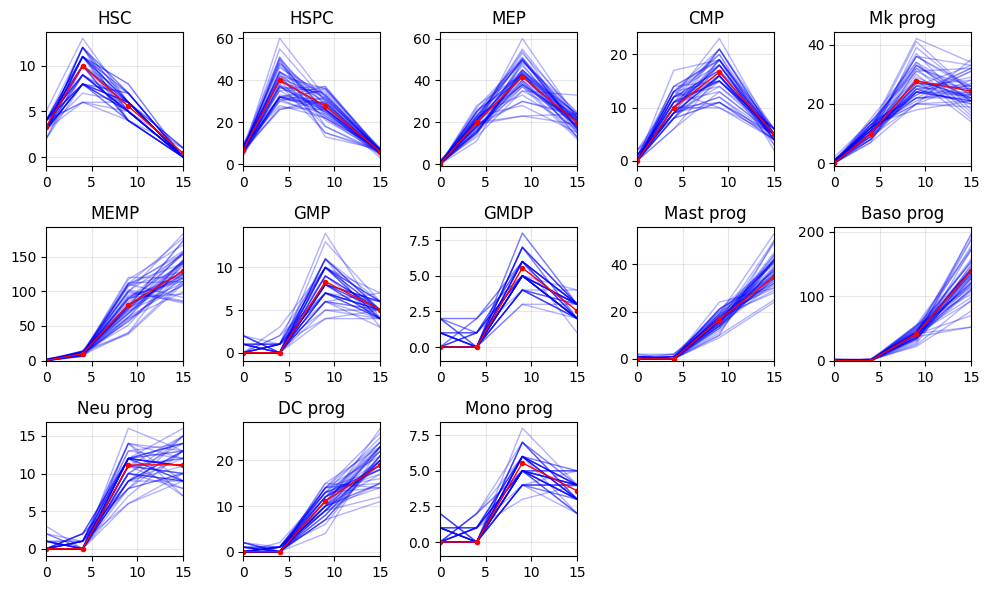


Simulation complete. Data saved to: in_silico/simulated_data/simulated_clones_meta3.csv
Data shape: (50, 52) (50 replicates x 52 features)


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import os

# ---------------------------------------------------------
# 1. Set Random Seed and Generate Parameters
# ---------------------------------------------------------

# Set seed for parameter generation (matches MATLAB rng(300))
np.random.seed(300)

# Generate parameters with random noise
p_hsc = 0.2 + np.random.randn() * 0.02
d_hsc = 0.1 + np.random.randn() * 0.01
m_hsc = 0.02 + np.random.randn() * 0.002

p_hspc = 0.3 + np.random.randn() * 0.03
d_hspc = 0.1 + np.random.randn() * 0.01
m_hspc = 0.011 + np.random.randn() * 0.0011

p_mep = 0.41 + np.random.randn() * 0.041
d_mep = 0.11 + np.random.randn() * 0.011
m_mep = 0.012 + np.random.randn() * 0.0012

p_cmp = 0.2 + np.random.randn() * 0.02
d_cmp = 0.09 + np.random.randn() * 0.009
m_cmp = 0.02 + np.random.randn() * 0.002

p_mk = 0.29 + np.random.randn() * 0.029
m_mk = 0.02 + np.random.randn() * 0.002

p_memp = 0.6 + np.random.randn() * 0.06
d_memp = 0.1 + np.random.randn() * 0.01
m_memp = 0.015 + np.random.randn() * 0.0015

p_gmp = 0.5 + np.random.randn() * 0.05
d_gmp = 0.3 + np.random.randn() * 0.03
m_gmp = 0.018 + np.random.randn() * 0.0018

p_gmdp = 0.4 + np.random.randn() * 0.04
d_gmdp = 0.3 + np.random.randn() * 0.03
m_gmdp = 0.071 + np.random.randn() * 0.0071

p_mast = 0.2 + np.random.randn() * 0.06
m_mast = 0.08 + np.random.randn() * 0.008

p_baso = 0.51 + np.random.randn() * 0.051
m_baso = 0.02 + np.random.randn() * 0.002

p_neu = 0.3 + np.random.randn() * 0.03
m_neu = 0.133 + np.random.randn() * 0.0133

p_dc = 0.6 + np.random.randn() * 0.06
m_dc = 0.11 + np.random.randn() * 0.011

p_mono = 0.145 + np.random.randn() * 0.0145
m_mono = 0.012 + np.random.randn() * 0.0012

print("Generated parameters:")
print(f"p_hsc={p_hsc:.4f}, d_hsc={d_hsc:.4f}, m_hsc={m_hsc:.4f}")
print(f"p_hspc={p_hspc:.4f}, d_hspc={d_hspc:.4f}, m_hspc={m_hspc:.4f}")

# ---------------------------------------------------------
# 2. Define ODE System with Generated Parameters
# ---------------------------------------------------------

def hematopoietic_model(t, y):
    dydt = np.zeros_like(y)
    x = y 

    # ODE Equations (using globally generated parameters)
    dydt[0] = (p_hsc - d_hsc - m_hsc) * x[0] 
    dydt[1] = (p_hspc - d_hspc - m_hspc) * x[1] + d_hsc * x[0]
    dydt[2] = (p_mep - d_mep - m_mep) * x[2] + d_hspc * x[1]
    dydt[3] = (p_cmp - d_cmp - m_cmp) * x[3] + d_hspc * x[1]
    dydt[4] = (p_mk - m_mk) * x[4] + d_mep * x[2]
    dydt[5] = (p_memp - d_memp - m_memp) * x[5] + d_mep * x[2] + d_cmp * x[3]
    dydt[6] = (p_gmp - d_gmp - m_gmp) * x[6] + d_cmp * x[3]
    dydt[7] = (p_gmdp - d_gmdp - m_gmdp) * x[7] + d_cmp * x[3]
    dydt[8] = (p_mast - m_mast) * x[8] + d_memp * x[5]
    dydt[9] = (p_baso - m_baso) * x[9] + d_memp * x[5]
    dydt[10] = (p_neu - m_neu) * x[10] + d_gmp * x[6]
    dydt[11] = (p_dc - m_dc) * x[11] + d_gmdp * x[7]
    dydt[12] = (p_mono - m_mono) * x[12] + d_gmdp * x[7]

    return dydt

# ---------------------------------------------------------
# 3. Simulation Setup
# ---------------------------------------------------------

cell_types = ['HSC', 'HSPC', 'MEP', 'CMP', 'Mk prog', 'MEMP', 
              'GMP', 'GMDP', 'Mast prog', 'Baso prog', 'Neu prog', 
              'DC prog', 'Mono prog']

time_points = np.array([0, 4, 9, 15])
t_plot = np.linspace(0, 20, 2001)

# Initial Conditions: HSC=1, HSPC=2, others=0
I0 = np.zeros(13)
I0[0] = 1.0  # HSC
I0[1] = 2.0  # HSPC

# ---------------------------------------------------------
# 4. Solve ODEs (Deterministic)
# ---------------------------------------------------------

sol_plot = solve_ivp(hematopoietic_model, [0, 20], I0, t_eval=t_plot, method='RK45')
sol_sample = solve_ivp(hematopoietic_model, [0, 15], I0, t_eval=time_points, method='RK45')

# Determine model values at sampling points (Time x Cell)
model_deterministic = np.round(sol_sample.y.T)

# --- SCALING SECTION ---
# Calculate current sum across cells for each timepoint
current_sums = model_deterministic.sum(axis=1, keepdims=True)

# Target sums for each timepoint: [10, 100, 300, 400]
target_sums = np.array([10, 100, 300, 400]).reshape(-1, 1)

# Normalize and Scale: (Model / Current_Sum) * Target_Sum
model_deterministic = (model_deterministic / current_sums) * target_sums
# ----------------------

# Calculate deviation
dev = model_deterministic * 0.2
dev[dev == 0] = 1 

# ---------------------------------------------------------
# 5. Generate Noise Replicates
# ---------------------------------------------------------

num_replicates = 50
model_noise_store = np.zeros((num_replicates, len(time_points) * 13))
all_noisy_trajectories = [] 

for nn in range(1, num_replicates + 1):
    np.random.seed(nn)
    
    noise = np.random.randn(*model_deterministic.shape) * dev
    model_noise = model_deterministic + noise
    
    model_noise = np.round(model_noise)
    model_noise[model_noise < 0] = 0
    
    # Store flattened (row-major)
    model_noise_store[nn-1, :] = model_noise.flatten() 
    all_noisy_trajectories.append(model_noise)

# ---------------------------------------------------------
# 6. Plotting
# ---------------------------------------------------------

fig, axes = plt.subplots(3, 5, figsize=(10, 6))
axes = axes.flatten()

for j in range(13):
    ax = axes[j]
    
    # Plot noisy replicates (the actual saved data)
    for noisy_data in all_noisy_trajectories:
        ax.plot(time_points, noisy_data[:, j], '-b', alpha=0.3, linewidth=1)
    
    # Plot mean of scaled deterministic model at sample points
    ax.plot(time_points, model_deterministic[:, j], '-ro', linewidth=1, 
            markersize=3, label='Scaled model' if j==0 else "")

    ax.set_title(cell_types[j])
    ax.set_ylim(bottom=-1)
    ax.set_xlim([0, 15])  # Match data range
    ax.grid(True, alpha=0.3)

axes[13].axis('off')
axes[14].axis('off')

if axes[0].get_legend():
    axes[0].legend()

plt.tight_layout()
plt.show()


# ---------------------------------------------------------
# 7. Saving Data
# ---------------------------------------------------------

output_folder = "in_silico/simulated_data/"
filename = "simulated_clones_meta3.csv"
file_path = os.path.join(output_folder, filename)

if not os.path.exists(output_folder):
    os.makedirs(output_folder)

# COMMENT: Saving the meta3 scaled simulated noise data to CSV
np.savetxt(file_path, model_noise_store, delimiter=",", fmt='%.4f')

print(f"\nSimulation complete. Data saved to: {file_path}")
print(f"Data shape: {model_noise_store.shape} ({num_replicates} replicates x {len(time_points)*13} features)")

# 4. Stochastic Baseline - Seed 400 (Meta4)

**Metaclone Type**: Standard stochastic parameter generation.
- **Initial Conditions**: HSC = 1.0, HSPC = 2.0.
- **Target Sums**: Rescaled to standard population sizes of `[10, 100, 300, 400]`.
- **Parameters**: Generated stochastically using random seed `400`. Normal Mast Cell proliferation rate (`p_mast = 0.6`).
- **Replicates**: 40 noise replicates.


Generated parameters:
p_hsc=0.1774, d_hsc=0.1070, m_hsc=0.0191
p_hspc=0.3222, d_hspc=0.0952, m_hspc=0.0125


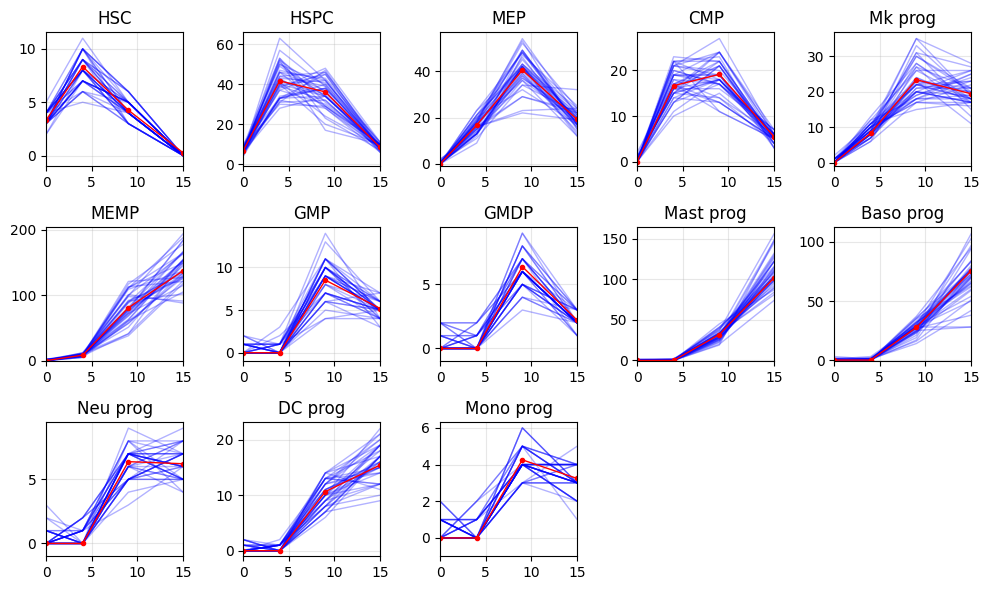


Simulation complete. Data saved to: in_silico/simulated_data/simulated_clones_meta4.csv
Data shape: (40, 52) (40 replicates x 52 features)


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import os

# ---------------------------------------------------------
# 1. Set Random Seed and Generate Parameters
# ---------------------------------------------------------

# Set seed for parameter generation (matches MATLAB rng(300))
np.random.seed(400)

# Generate parameters with random noise
p_hsc = 0.2 + np.random.randn() * 0.02
d_hsc = 0.1 + np.random.randn() * 0.01
m_hsc = 0.02 + np.random.randn() * 0.002

p_hspc = 0.3 + np.random.randn() * 0.03
d_hspc = 0.1 + np.random.randn() * 0.01
m_hspc = 0.011 + np.random.randn() * 0.0011

p_mep = 0.41 + np.random.randn() * 0.041
d_mep = 0.11 + np.random.randn() * 0.011
m_mep = 0.012 + np.random.randn() * 0.0012

p_cmp = 0.2 + np.random.randn() * 0.02
d_cmp = 0.09 + np.random.randn() * 0.009
m_cmp = 0.02 + np.random.randn() * 0.002

p_mk = 0.29 + np.random.randn() * 0.029
m_mk = 0.02 + np.random.randn() * 0.002

p_memp = 0.6 + np.random.randn() * 0.06
d_memp = 0.1 + np.random.randn() * 0.01
m_memp = 0.015 + np.random.randn() * 0.0015

p_gmp = 0.5 + np.random.randn() * 0.05
d_gmp = 0.3 + np.random.randn() * 0.03
m_gmp = 0.018 + np.random.randn() * 0.0018

p_gmdp = 0.4 + np.random.randn() * 0.04
d_gmdp = 0.3 + np.random.randn() * 0.03
m_gmdp = 0.071 + np.random.randn() * 0.0071

p_mast = 0.6 + np.random.randn() * 0.06
m_mast = 0.08 + np.random.randn() * 0.008

p_baso = 0.51 + np.random.randn() * 0.051
m_baso = 0.02 + np.random.randn() * 0.002

p_neu = 0.3 + np.random.randn() * 0.03
m_neu = 0.133 + np.random.randn() * 0.0133

p_dc = 0.6 + np.random.randn() * 0.06
m_dc = 0.11 + np.random.randn() * 0.011

p_mono = 0.145 + np.random.randn() * 0.0145
m_mono = 0.012 + np.random.randn() * 0.0012

print("Generated parameters:")
print(f"p_hsc={p_hsc:.4f}, d_hsc={d_hsc:.4f}, m_hsc={m_hsc:.4f}")
print(f"p_hspc={p_hspc:.4f}, d_hspc={d_hspc:.4f}, m_hspc={m_hspc:.4f}")

# ---------------------------------------------------------
# 2. Define ODE System with Generated Parameters
# ---------------------------------------------------------

def hematopoietic_model(t, y):
    dydt = np.zeros_like(y)
    x = y 

    # ODE Equations (using globally generated parameters)
    dydt[0] = (p_hsc - d_hsc - m_hsc) * x[0] 
    dydt[1] = (p_hspc - d_hspc - m_hspc) * x[1] + d_hsc * x[0]
    dydt[2] = (p_mep - d_mep - m_mep) * x[2] + d_hspc * x[1]
    dydt[3] = (p_cmp - d_cmp - m_cmp) * x[3] + d_hspc * x[1]
    dydt[4] = (p_mk - m_mk) * x[4] + d_mep * x[2]
    dydt[5] = (p_memp - d_memp - m_memp) * x[5] + d_mep * x[2] + d_cmp * x[3]
    dydt[6] = (p_gmp - d_gmp - m_gmp) * x[6] + d_cmp * x[3]
    dydt[7] = (p_gmdp - d_gmdp - m_gmdp) * x[7] + d_cmp * x[3]
    dydt[8] = (p_mast - m_mast) * x[8] + d_memp * x[5]
    dydt[9] = (p_baso - m_baso) * x[9] + d_memp * x[5]
    dydt[10] = (p_neu - m_neu) * x[10] + d_gmp * x[6]
    dydt[11] = (p_dc - m_dc) * x[11] + d_gmdp * x[7]
    dydt[12] = (p_mono - m_mono) * x[12] + d_gmdp * x[7]

    return dydt

# ---------------------------------------------------------
# 3. Simulation Setup
# ---------------------------------------------------------

cell_types = ['HSC', 'HSPC', 'MEP', 'CMP', 'Mk prog', 'MEMP', 
              'GMP', 'GMDP', 'Mast prog', 'Baso prog', 'Neu prog', 
              'DC prog', 'Mono prog']

time_points = np.array([0, 4, 9, 15])
t_plot = np.linspace(0, 20, 2001)

# Initial Conditions: HSC=1, HSPC=2, others=0
I0 = np.zeros(13)
I0[0] = 1.0  # HSC
I0[1] = 2.0  # HSPC

# ---------------------------------------------------------
# 4. Solve ODEs (Deterministic)
# ---------------------------------------------------------

sol_plot = solve_ivp(hematopoietic_model, [0, 20], I0, t_eval=t_plot, method='RK45')
sol_sample = solve_ivp(hematopoietic_model, [0, 15], I0, t_eval=time_points, method='RK45')

# Determine model values at sampling points (Time x Cell)
model_deterministic = np.round(sol_sample.y.T)

# --- SCALING SECTION ---
# Calculate current sum across cells for each timepoint
current_sums = model_deterministic.sum(axis=1, keepdims=True)

# Target sums for each timepoint: [10, 100, 300, 400]
target_sums = np.array([10, 100, 300, 400]).reshape(-1, 1)

# Normalize and Scale: (Model / Current_Sum) * Target_Sum
model_deterministic = (model_deterministic / current_sums) * target_sums
# ----------------------

# Calculate deviation
dev = model_deterministic * 0.2
dev[dev == 0] = 1 

# ---------------------------------------------------------
# 5. Generate Noise Replicates
# ---------------------------------------------------------

num_replicates = 40
model_noise_store = np.zeros((num_replicates, len(time_points) * 13))
all_noisy_trajectories = [] 

for nn in range(1, num_replicates + 1):
    np.random.seed(nn)
    
    noise = np.random.randn(*model_deterministic.shape) * dev
    model_noise = model_deterministic + noise
    
    model_noise = np.round(model_noise)
    model_noise[model_noise < 0] = 0
    
    # Store flattened (row-major)
    model_noise_store[nn-1, :] = model_noise.flatten() 
    all_noisy_trajectories.append(model_noise)

# ---------------------------------------------------------
# 6. Plotting
# ---------------------------------------------------------

fig, axes = plt.subplots(3, 5, figsize=(10, 6))
axes = axes.flatten()

for j in range(13):
    ax = axes[j]
    
    # Plot noisy replicates (the actual saved data)
    for noisy_data in all_noisy_trajectories:
        ax.plot(time_points, noisy_data[:, j], '-b', alpha=0.3, linewidth=1)
    
    # Plot mean of scaled deterministic model at sample points
    ax.plot(time_points, model_deterministic[:, j], '-ro', linewidth=1, 
            markersize=3, label='Scaled model' if j==0 else "")

    ax.set_title(cell_types[j])
    ax.set_ylim(bottom=-1)
    ax.set_xlim([0, 15])  # Match data range
    ax.grid(True, alpha=0.3)

axes[13].axis('off')
axes[14].axis('off')

if axes[0].get_legend():
    axes[0].legend()

plt.tight_layout()
plt.show()


# ---------------------------------------------------------
# 7. Saving Data
# ---------------------------------------------------------

output_folder = "in_silico/simulated_data/"
filename = "simulated_clones_meta4.csv"
file_path = os.path.join(output_folder, filename)

if not os.path.exists(output_folder):
    os.makedirs(output_folder)

# COMMENT: Saving the meta4 scaled simulated noise data to CSV
np.savetxt(file_path, model_noise_store, delimiter=",", fmt='%.4f')

print(f"\nSimulation complete. Data saved to: {file_path}")
print(f"Data shape: {model_noise_store.shape} ({num_replicates} replicates x {len(time_points)*13} features)")

# 5. Stochastic Baseline - Seed 500 (Meta5)

**Metaclone Type**: Standard stochastic parameter generation.
- **Initial Conditions**: HSC = 1.0, HSPC = 2.0.
- **Target Sums**: Rescaled to standard population sizes of `[10, 100, 300, 400]`.
- **Parameters**: Generated stochastically using random seed `500` (identical model configuration to Meta4 but distinct seed).
- **Replicates**: 72 noise replicates.


Generated parameters:
p_hsc=0.1925, d_hsc=0.1017, m_hsc=0.0214
p_hspc=0.3576, d_hspc=0.0980, m_hspc=0.0102


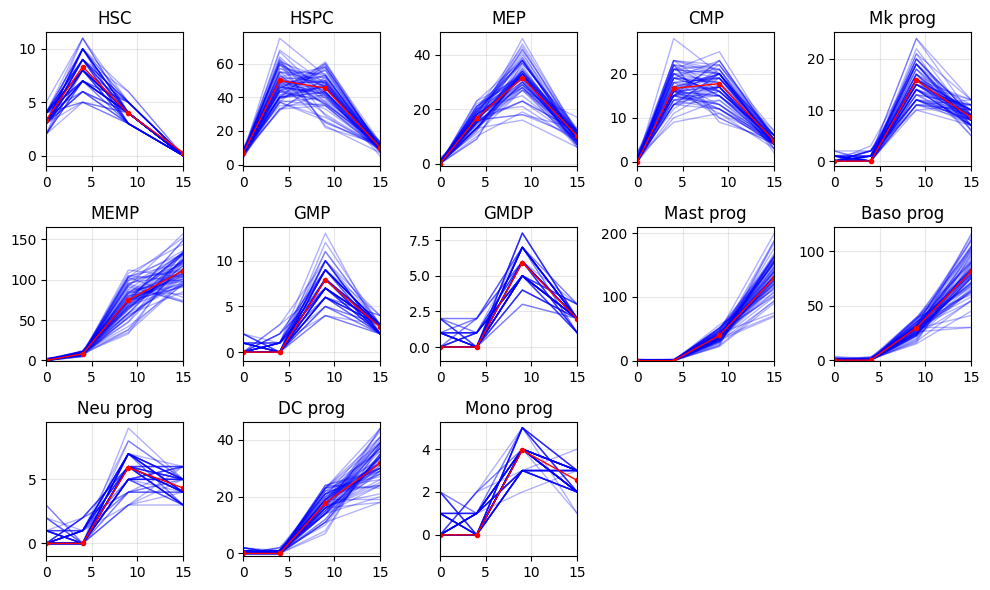


Simulation complete. Data saved to: in_silico/simulated_data/simulated_clones_meta5.csv
Data shape: (72, 52) (72 replicates x 52 features)


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import os

# ---------------------------------------------------------
# 1. Set Random Seed and Generate Parameters
# ---------------------------------------------------------

# Set seed for parameter generation (matches MATLAB rng(300))
np.random.seed(500)

# Generate parameters with random noise
p_hsc = 0.2 + np.random.randn() * 0.02
d_hsc = 0.1 + np.random.randn() * 0.01
m_hsc = 0.02 + np.random.randn() * 0.002

p_hspc = 0.3 + np.random.randn() * 0.03
d_hspc = 0.1 + np.random.randn() * 0.01
m_hspc = 0.011 + np.random.randn() * 0.0011

p_mep = 0.41 + np.random.randn() * 0.041
d_mep = 0.11 + np.random.randn() * 0.011
m_mep = 0.012 + np.random.randn() * 0.0012

p_cmp = 0.2 + np.random.randn() * 0.02
d_cmp = 0.09 + np.random.randn() * 0.009
m_cmp = 0.02 + np.random.randn() * 0.002

p_mk = 0.29 + np.random.randn() * 0.029
m_mk = 0.02 + np.random.randn() * 0.002

p_memp = 0.6 + np.random.randn() * 0.06
d_memp = 0.1 + np.random.randn() * 0.01
m_memp = 0.015 + np.random.randn() * 0.0015

p_gmp = 0.5 + np.random.randn() * 0.05
d_gmp = 0.3 + np.random.randn() * 0.03
m_gmp = 0.018 + np.random.randn() * 0.0018

p_gmdp = 0.4 + np.random.randn() * 0.04
d_gmdp = 0.3 + np.random.randn() * 0.03
m_gmdp = 0.071 + np.random.randn() * 0.0071

p_mast = 0.6 + np.random.randn() * 0.06
m_mast = 0.08 + np.random.randn() * 0.008

p_baso = 0.51 + np.random.randn() * 0.051
m_baso = 0.02 + np.random.randn() * 0.002

p_neu = 0.3 + np.random.randn() * 0.03
m_neu = 0.133 + np.random.randn() * 0.0133

p_dc = 0.6 + np.random.randn() * 0.06
m_dc = 0.11 + np.random.randn() * 0.011

p_mono = 0.145 + np.random.randn() * 0.0145
m_mono = 0.012 + np.random.randn() * 0.0012

print("Generated parameters:")
print(f"p_hsc={p_hsc:.4f}, d_hsc={d_hsc:.4f}, m_hsc={m_hsc:.4f}")
print(f"p_hspc={p_hspc:.4f}, d_hspc={d_hspc:.4f}, m_hspc={m_hspc:.4f}")

# ---------------------------------------------------------
# 2. Define ODE System with Generated Parameters
# ---------------------------------------------------------

def hematopoietic_model(t, y):
    dydt = np.zeros_like(y)
    x = y 

    # ODE Equations (using globally generated parameters)
    dydt[0] = (p_hsc - d_hsc - m_hsc) * x[0] 
    dydt[1] = (p_hspc - d_hspc - m_hspc) * x[1] + d_hsc * x[0]
    dydt[2] = (p_mep - d_mep - m_mep) * x[2] + d_hspc * x[1]
    dydt[3] = (p_cmp - d_cmp - m_cmp) * x[3] + d_hspc * x[1]
    dydt[4] = (p_mk - m_mk) * x[4] + d_mep * x[2]
    dydt[5] = (p_memp - d_memp - m_memp) * x[5] + d_mep * x[2] + d_cmp * x[3]
    dydt[6] = (p_gmp - d_gmp - m_gmp) * x[6] + d_cmp * x[3]
    dydt[7] = (p_gmdp - d_gmdp - m_gmdp) * x[7] + d_cmp * x[3]
    dydt[8] = (p_mast - m_mast) * x[8] + d_memp * x[5]
    dydt[9] = (p_baso - m_baso) * x[9] + d_memp * x[5]
    dydt[10] = (p_neu - m_neu) * x[10] + d_gmp * x[6]
    dydt[11] = (p_dc - m_dc) * x[11] + d_gmdp * x[7]
    dydt[12] = (p_mono - m_mono) * x[12] + d_gmdp * x[7]

    return dydt

# ---------------------------------------------------------
# 3. Simulation Setup
# ---------------------------------------------------------

cell_types = ['HSC', 'HSPC', 'MEP', 'CMP', 'Mk prog', 'MEMP', 
              'GMP', 'GMDP', 'Mast prog', 'Baso prog', 'Neu prog', 
              'DC prog', 'Mono prog']

time_points = np.array([0, 4, 9, 15])
t_plot = np.linspace(0, 20, 2001)

# Initial Conditions: HSC=1, HSPC=2, others=0
I0 = np.zeros(13)
I0[0] = 1.0  # HSC
I0[1] = 2.0  # HSPC

# ---------------------------------------------------------
# 4. Solve ODEs (Deterministic)
# ---------------------------------------------------------

sol_plot = solve_ivp(hematopoietic_model, [0, 20], I0, t_eval=t_plot, method='RK45')
sol_sample = solve_ivp(hematopoietic_model, [0, 15], I0, t_eval=time_points, method='RK45')

# Determine model values at sampling points (Time x Cell)
model_deterministic = np.round(sol_sample.y.T)

# --- SCALING SECTION ---
# Calculate current sum across cells for each timepoint
current_sums = model_deterministic.sum(axis=1, keepdims=True)

# Target sums for each timepoint: [10, 100, 300, 400]
target_sums = np.array([10, 100, 300, 400]).reshape(-1, 1)

# Normalize and Scale: (Model / Current_Sum) * Target_Sum
model_deterministic = (model_deterministic / current_sums) * target_sums
# ----------------------

# Calculate deviation
dev = model_deterministic * 0.2
dev[dev == 0] = 1 

# ---------------------------------------------------------
# 5. Generate Noise Replicates
# ---------------------------------------------------------

num_replicates = 72
model_noise_store = np.zeros((num_replicates, len(time_points) * 13))
all_noisy_trajectories = [] 

for nn in range(1, num_replicates + 1):
    np.random.seed(nn)
    
    noise = np.random.randn(*model_deterministic.shape) * dev
    model_noise = model_deterministic + noise
    
    model_noise = np.round(model_noise)
    model_noise[model_noise < 0] = 0
    
    # Store flattened (row-major)
    model_noise_store[nn-1, :] = model_noise.flatten() 
    all_noisy_trajectories.append(model_noise)

# ---------------------------------------------------------
# 6. Plotting
# ---------------------------------------------------------

fig, axes = plt.subplots(3, 5, figsize=(10, 6))
axes = axes.flatten()

for j in range(13):
    ax = axes[j]
    
    # Plot noisy replicates (the actual saved data)
    for noisy_data in all_noisy_trajectories:
        ax.plot(time_points, noisy_data[:, j], '-b', alpha=0.3, linewidth=1)
    
    # Plot mean of scaled deterministic model at sample points
    ax.plot(time_points, model_deterministic[:, j], '-ro', linewidth=1, 
            markersize=3, label='Scaled model' if j==0 else "")

    ax.set_title(cell_types[j])
    ax.set_ylim(bottom=-1)
    ax.set_xlim([0, 15])  # Match data range
    ax.grid(True, alpha=0.3)

axes[13].axis('off')
axes[14].axis('off')

if axes[0].get_legend():
    axes[0].legend()

plt.tight_layout()
plt.show()


# ---------------------------------------------------------
# 7. Saving Data
# ---------------------------------------------------------

output_folder = "in_silico/simulated_data/"
filename = "simulated_clones_meta5.csv"
file_path = os.path.join(output_folder, filename)

if not os.path.exists(output_folder):
    os.makedirs(output_folder)

# COMMENT: Saving the meta5 scaled simulated noise data to CSV
np.savetxt(file_path, model_noise_store, delimiter=",", fmt='%.4f')

print(f"\nSimulation complete. Data saved to: {file_path}")
print(f"Data shape: {model_noise_store.shape} ({num_replicates} replicates x {len(time_points)*13} features)")

# 6. Stochastic Baseline - Seed 600 (Meta6)

**Metaclone Type**: Standard stochastic parameter generation.
- **Initial Conditions**: HSC = 1.0, HSPC = 2.0.
- **Target Sums**: Rescaled to standard population sizes of `[10, 100, 300, 400]`.
- **Parameters**: Generated stochastically using random seed `600` (identical model configuration to Meta4/5 but distinct seed).
- **Replicates**: 56 noise replicates.


Generated parameters:
p_hsc=0.2009, d_hsc=0.0950, m_hsc=0.0175
p_hspc=0.2845, d_hspc=0.1051, m_hspc=0.0107


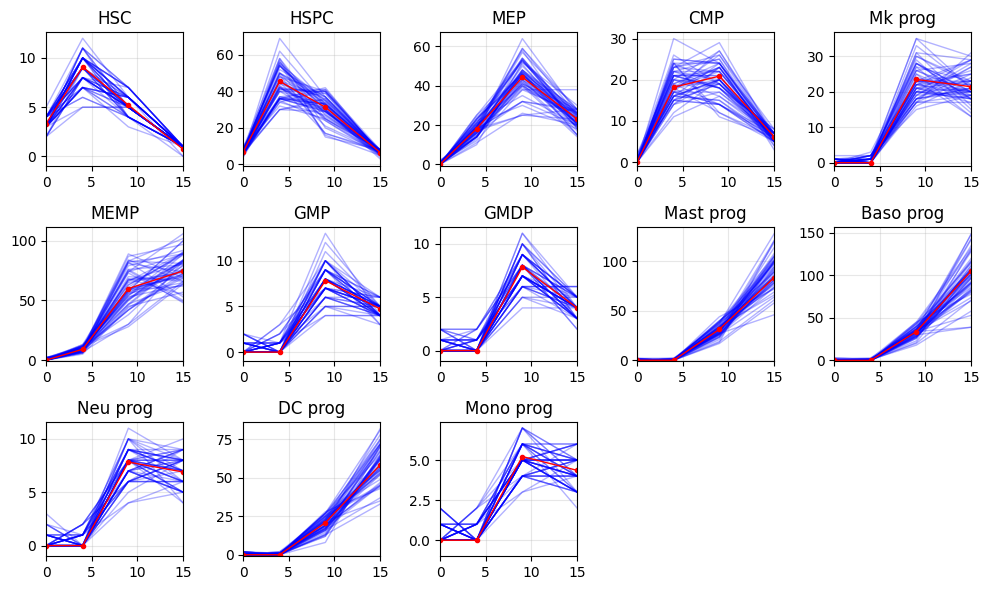


Simulation complete. Data saved to: in_silico/simulated_data/simulated_clones_meta6.csv
Data shape: (56, 52) (56 replicates x 52 features)


In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import os

# ---------------------------------------------------------
# 1. Set Random Seed and Generate Parameters
# ---------------------------------------------------------

# Set seed for parameter generation (matches MATLAB rng(300))
np.random.seed(600)

# Generate parameters with random noise
p_hsc = 0.2 + np.random.randn() * 0.02
d_hsc = 0.1 + np.random.randn() * 0.01
m_hsc = 0.02 + np.random.randn() * 0.002

p_hspc = 0.3 + np.random.randn() * 0.03
d_hspc = 0.1 + np.random.randn() * 0.01
m_hspc = 0.011 + np.random.randn() * 0.0011

p_mep = 0.41 + np.random.randn() * 0.041
d_mep = 0.11 + np.random.randn() * 0.011
m_mep = 0.012 + np.random.randn() * 0.0012

p_cmp = 0.2 + np.random.randn() * 0.02
d_cmp = 0.09 + np.random.randn() * 0.009
m_cmp = 0.02 + np.random.randn() * 0.002

p_mk = 0.29 + np.random.randn() * 0.029
m_mk = 0.02 + np.random.randn() * 0.002

p_memp = 0.6 + np.random.randn() * 0.06
d_memp = 0.1 + np.random.randn() * 0.01
m_memp = 0.015 + np.random.randn() * 0.0015

p_gmp = 0.5 + np.random.randn() * 0.05
d_gmp = 0.3 + np.random.randn() * 0.03
m_gmp = 0.018 + np.random.randn() * 0.0018

p_gmdp = 0.4 + np.random.randn() * 0.04
d_gmdp = 0.3 + np.random.randn() * 0.03
m_gmdp = 0.071 + np.random.randn() * 0.0071

p_mast = 0.6 + np.random.randn() * 0.06
m_mast = 0.08 + np.random.randn() * 0.008

p_baso = 0.51 + np.random.randn() * 0.051
m_baso = 0.02 + np.random.randn() * 0.002

p_neu = 0.3 + np.random.randn() * 0.03
m_neu = 0.133 + np.random.randn() * 0.0133

p_dc = 0.6 + np.random.randn() * 0.06
m_dc = 0.11 + np.random.randn() * 0.011

p_mono = 0.145 + np.random.randn() * 0.0145
m_mono = 0.012 + np.random.randn() * 0.0012

print("Generated parameters:")
print(f"p_hsc={p_hsc:.4f}, d_hsc={d_hsc:.4f}, m_hsc={m_hsc:.4f}")
print(f"p_hspc={p_hspc:.4f}, d_hspc={d_hspc:.4f}, m_hspc={m_hspc:.4f}")

# ---------------------------------------------------------
# 2. Define ODE System with Generated Parameters
# ---------------------------------------------------------

def hematopoietic_model(t, y):
    dydt = np.zeros_like(y)
    x = y 

    # ODE Equations (using globally generated parameters)
    dydt[0] = (p_hsc - d_hsc - m_hsc) * x[0] 
    dydt[1] = (p_hspc - d_hspc - m_hspc) * x[1] + d_hsc * x[0]
    dydt[2] = (p_mep - d_mep - m_mep) * x[2] + d_hspc * x[1]
    dydt[3] = (p_cmp - d_cmp - m_cmp) * x[3] + d_hspc * x[1]
    dydt[4] = (p_mk - m_mk) * x[4] + d_mep * x[2]
    dydt[5] = (p_memp - d_memp - m_memp) * x[5] + d_mep * x[2] + d_cmp * x[3]
    dydt[6] = (p_gmp - d_gmp - m_gmp) * x[6] + d_cmp * x[3]
    dydt[7] = (p_gmdp - d_gmdp - m_gmdp) * x[7] + d_cmp * x[3]
    dydt[8] = (p_mast - m_mast) * x[8] + d_memp * x[5]
    dydt[9] = (p_baso - m_baso) * x[9] + d_memp * x[5]
    dydt[10] = (p_neu - m_neu) * x[10] + d_gmp * x[6]
    dydt[11] = (p_dc - m_dc) * x[11] + d_gmdp * x[7]
    dydt[12] = (p_mono - m_mono) * x[12] + d_gmdp * x[7]

    return dydt

# ---------------------------------------------------------
# 3. Simulation Setup
# ---------------------------------------------------------

cell_types = ['HSC', 'HSPC', 'MEP', 'CMP', 'Mk prog', 'MEMP', 
              'GMP', 'GMDP', 'Mast prog', 'Baso prog', 'Neu prog', 
              'DC prog', 'Mono prog']

time_points = np.array([0, 4, 9, 15])
t_plot = np.linspace(0, 20, 2001)

# Initial Conditions: HSC=1, HSPC=2, others=0
I0 = np.zeros(13)
I0[0] = 1.0  # HSC
I0[1] = 2.0  # HSPC

# ---------------------------------------------------------
# 4. Solve ODEs (Deterministic)
# ---------------------------------------------------------

sol_plot = solve_ivp(hematopoietic_model, [0, 20], I0, t_eval=t_plot, method='RK45')
sol_sample = solve_ivp(hematopoietic_model, [0, 15], I0, t_eval=time_points, method='RK45')

# Determine model values at sampling points (Time x Cell)
model_deterministic = np.round(sol_sample.y.T)

# --- SCALING SECTION ---
# Calculate current sum across cells for each timepoint
current_sums = model_deterministic.sum(axis=1, keepdims=True)

# Target sums for each timepoint: [10, 100, 300, 400]
target_sums = np.array([10, 100, 300, 400]).reshape(-1, 1)

# Normalize and Scale: (Model / Current_Sum) * Target_Sum
model_deterministic = (model_deterministic / current_sums) * target_sums
# ----------------------

# Calculate deviation
dev = model_deterministic * 0.2
dev[dev == 0] = 1 

# ---------------------------------------------------------
# 5. Generate Noise Replicates
# ---------------------------------------------------------

num_replicates = 56
model_noise_store = np.zeros((num_replicates, len(time_points) * 13))
all_noisy_trajectories = [] 

for nn in range(1, num_replicates + 1):
    np.random.seed(nn)
    
    noise = np.random.randn(*model_deterministic.shape) * dev
    model_noise = model_deterministic + noise
    
    model_noise = np.round(model_noise)
    model_noise[model_noise < 0] = 0
    
    # Store flattened (row-major)
    model_noise_store[nn-1, :] = model_noise.flatten() 
    all_noisy_trajectories.append(model_noise)

# ---------------------------------------------------------
# 6. Plotting
# ---------------------------------------------------------

fig, axes = plt.subplots(3, 5, figsize=(10, 6))
axes = axes.flatten()

for j in range(13):
    ax = axes[j]
    
    # Plot noisy replicates (the actual saved data)
    for noisy_data in all_noisy_trajectories:
        ax.plot(time_points, noisy_data[:, j], '-b', alpha=0.3, linewidth=1)
    
    # Plot mean of scaled deterministic model at sample points
    ax.plot(time_points, model_deterministic[:, j], '-ro', linewidth=1, 
            markersize=3, label='Scaled model' if j==0 else "")

    ax.set_title(cell_types[j])
    ax.set_ylim(bottom=-1)
    ax.set_xlim([0, 15])  # Match data range
    ax.grid(True, alpha=0.3)

axes[13].axis('off')
axes[14].axis('off')

if axes[0].get_legend():
    axes[0].legend()

plt.tight_layout()
plt.show()


# ---------------------------------------------------------
# 7. Saving Data
# ---------------------------------------------------------

output_folder = "in_silico/simulated_data/"
filename = "simulated_clones_meta6.csv"
file_path = os.path.join(output_folder, filename)

if not os.path.exists(output_folder):
    os.makedirs(output_folder)

# COMMENT: Saving the meta6 scaled simulated noise data to CSV
np.savetxt(file_path, model_noise_store, delimiter=",", fmt='%.4f')

print(f"\nSimulation complete. Data saved to: {file_path}")
print(f"Data shape: {model_noise_store.shape} ({num_replicates} replicates x {len(time_points)*13} features)")

# 7. Stochastic Baseline - Seed 700 (Meta7)

**Metaclone Type**: Standard stochastic parameter generation.
- **Initial Conditions**: HSC = 1.0, HSPC = 2.0.
- **Target Sums**: Rescaled to standard population sizes of `[10, 100, 300, 400]`.
- **Parameters**: Generated stochastically using random seed `700` (identical model configuration to Meta4/5/6 but distinct seed).
- **Replicates**: 88 noise replicates.


Generated parameters:
p_hsc=0.1945, d_hsc=0.0885, m_hsc=0.0221
p_hspc=0.2739, d_hspc=0.0824, m_hspc=0.0099


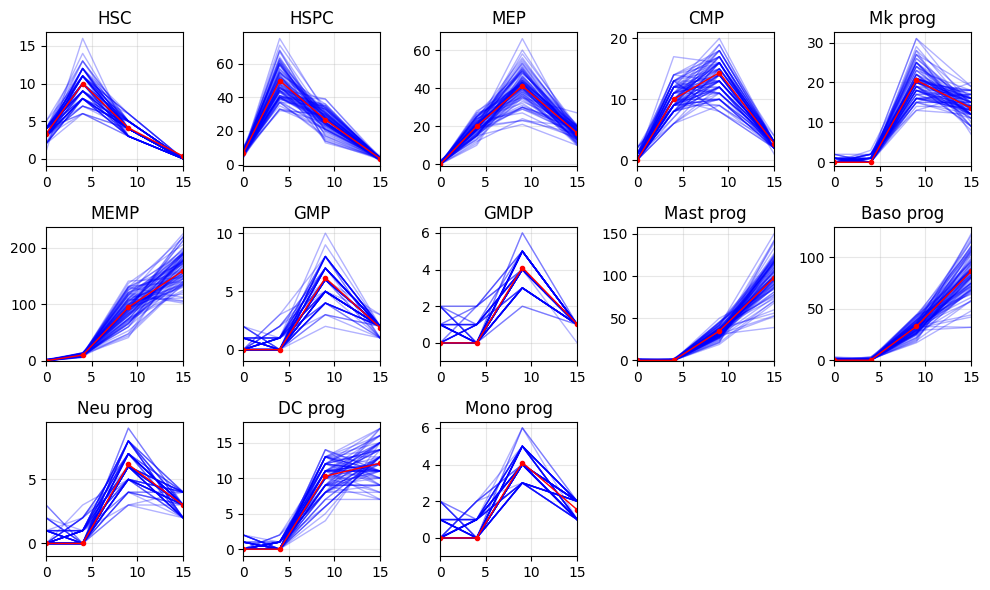


Simulation complete. Data saved to: in_silico/simulated_data/simulated_clones_meta7.csv
Data shape: (88, 52) (88 replicates x 52 features)


In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import os

# ---------------------------------------------------------
# 1. Set Random Seed and Generate Parameters
# ---------------------------------------------------------

# Set seed for parameter generation (matches MATLAB rng(300))
np.random.seed(700)

# Generate parameters with random noise
p_hsc = 0.2 + np.random.randn() * 0.02
d_hsc = 0.1 + np.random.randn() * 0.01
m_hsc = 0.02 + np.random.randn() * 0.002

p_hspc = 0.3 + np.random.randn() * 0.03
d_hspc = 0.1 + np.random.randn() * 0.01
m_hspc = 0.011 + np.random.randn() * 0.0011

p_mep = 0.41 + np.random.randn() * 0.041
d_mep = 0.11 + np.random.randn() * 0.011
m_mep = 0.012 + np.random.randn() * 0.0012

p_cmp = 0.2 + np.random.randn() * 0.02
d_cmp = 0.09 + np.random.randn() * 0.009
m_cmp = 0.02 + np.random.randn() * 0.002

p_mk = 0.29 + np.random.randn() * 0.029
m_mk = 0.02 + np.random.randn() * 0.002

p_memp = 0.6 + np.random.randn() * 0.06
d_memp = 0.1 + np.random.randn() * 0.01
m_memp = 0.015 + np.random.randn() * 0.0015

p_gmp = 0.5 + np.random.randn() * 0.05
d_gmp = 0.3 + np.random.randn() * 0.03
m_gmp = 0.018 + np.random.randn() * 0.0018

p_gmdp = 0.4 + np.random.randn() * 0.04
d_gmdp = 0.3 + np.random.randn() * 0.03
m_gmdp = 0.071 + np.random.randn() * 0.0071

p_mast = 0.6 + np.random.randn() * 0.06
m_mast = 0.08 + np.random.randn() * 0.008

p_baso = 0.51 + np.random.randn() * 0.051
m_baso = 0.02 + np.random.randn() * 0.002

p_neu = 0.3 + np.random.randn() * 0.03
m_neu = 0.133 + np.random.randn() * 0.0133

p_dc = 0.6 + np.random.randn() * 0.06
m_dc = 0.11 + np.random.randn() * 0.011

p_mono = 0.145 + np.random.randn() * 0.0145
m_mono = 0.012 + np.random.randn() * 0.0012

print("Generated parameters:")
print(f"p_hsc={p_hsc:.4f}, d_hsc={d_hsc:.4f}, m_hsc={m_hsc:.4f}")
print(f"p_hspc={p_hspc:.4f}, d_hspc={d_hspc:.4f}, m_hspc={m_hspc:.4f}")

# ---------------------------------------------------------
# 2. Define ODE System with Generated Parameters
# ---------------------------------------------------------

def hematopoietic_model(t, y):
    dydt = np.zeros_like(y)
    x = y 

    # ODE Equations (using globally generated parameters)
    dydt[0] = (p_hsc - d_hsc - m_hsc) * x[0] 
    dydt[1] = (p_hspc - d_hspc - m_hspc) * x[1] + d_hsc * x[0]
    dydt[2] = (p_mep - d_mep - m_mep) * x[2] + d_hspc * x[1]
    dydt[3] = (p_cmp - d_cmp - m_cmp) * x[3] + d_hspc * x[1]
    dydt[4] = (p_mk - m_mk) * x[4] + d_mep * x[2]
    dydt[5] = (p_memp - d_memp - m_memp) * x[5] + d_mep * x[2] + d_cmp * x[3]
    dydt[6] = (p_gmp - d_gmp - m_gmp) * x[6] + d_cmp * x[3]
    dydt[7] = (p_gmdp - d_gmdp - m_gmdp) * x[7] + d_cmp * x[3]
    dydt[8] = (p_mast - m_mast) * x[8] + d_memp * x[5]
    dydt[9] = (p_baso - m_baso) * x[9] + d_memp * x[5]
    dydt[10] = (p_neu - m_neu) * x[10] + d_gmp * x[6]
    dydt[11] = (p_dc - m_dc) * x[11] + d_gmdp * x[7]
    dydt[12] = (p_mono - m_mono) * x[12] + d_gmdp * x[7]

    return dydt

# ---------------------------------------------------------
# 3. Simulation Setup
# ---------------------------------------------------------

cell_types = ['HSC', 'HSPC', 'MEP', 'CMP', 'Mk prog', 'MEMP', 
              'GMP', 'GMDP', 'Mast prog', 'Baso prog', 'Neu prog', 
              'DC prog', 'Mono prog']

time_points = np.array([0, 4, 9, 15])
t_plot = np.linspace(0, 20, 2001)

# Initial Conditions: HSC=1, HSPC=2, others=0
I0 = np.zeros(13)
I0[0] = 1.0  # HSC
I0[1] = 2.0  # HSPC

# ---------------------------------------------------------
# 4. Solve ODEs (Deterministic)
# ---------------------------------------------------------

sol_plot = solve_ivp(hematopoietic_model, [0, 20], I0, t_eval=t_plot, method='RK45')
sol_sample = solve_ivp(hematopoietic_model, [0, 15], I0, t_eval=time_points, method='RK45')

# Determine model values at sampling points (Time x Cell)
model_deterministic = np.round(sol_sample.y.T)

# --- SCALING SECTION ---
# Calculate current sum across cells for each timepoint
current_sums = model_deterministic.sum(axis=1, keepdims=True)

# Target sums for each timepoint: [10, 100, 300, 400]
target_sums = np.array([10, 100, 300, 400]).reshape(-1, 1)

# Normalize and Scale: (Model / Current_Sum) * Target_Sum
model_deterministic = (model_deterministic / current_sums) * target_sums
# ----------------------

# Calculate deviation
dev = model_deterministic * 0.2
dev[dev == 0] = 1 

# ---------------------------------------------------------
# 5. Generate Noise Replicates
# ---------------------------------------------------------

num_replicates = 88
model_noise_store = np.zeros((num_replicates, len(time_points) * 13))
all_noisy_trajectories = [] 

for nn in range(1, num_replicates + 1):
    np.random.seed(nn)
    
    noise = np.random.randn(*model_deterministic.shape) * dev
    model_noise = model_deterministic + noise
    
    model_noise = np.round(model_noise)
    model_noise[model_noise < 0] = 0
    
    # Store flattened (row-major)
    model_noise_store[nn-1, :] = model_noise.flatten() 
    all_noisy_trajectories.append(model_noise)

# ---------------------------------------------------------
# 6. Plotting
# ---------------------------------------------------------

fig, axes = plt.subplots(3, 5, figsize=(10, 6))
axes = axes.flatten()

for j in range(13):
    ax = axes[j]
    
    # Plot noisy replicates (the actual saved data)
    for noisy_data in all_noisy_trajectories:
        ax.plot(time_points, noisy_data[:, j], '-b', alpha=0.3, linewidth=1)
    
    # Plot mean of scaled deterministic model at sample points
    ax.plot(time_points, model_deterministic[:, j], '-ro', linewidth=1, 
            markersize=3, label='Scaled model' if j==0 else "")

    ax.set_title(cell_types[j])
    ax.set_ylim(bottom=-1)
    ax.set_xlim([0, 15])  # Match data range
    ax.grid(True, alpha=0.3)

axes[13].axis('off')
axes[14].axis('off')

if axes[0].get_legend():
    axes[0].legend()

plt.tight_layout()
plt.show()


# ---------------------------------------------------------
# 7. Saving Data
# ---------------------------------------------------------

output_folder = "in_silico/simulated_data/"
filename = "simulated_clones_meta7.csv"
file_path = os.path.join(output_folder, filename)

if not os.path.exists(output_folder):
    os.makedirs(output_folder)

# COMMENT: Saving the meta7 scaled simulated noise data to CSV
np.savetxt(file_path, model_noise_store, delimiter=",", fmt='%.4f')

print(f"\nSimulation complete. Data saved to: {file_path}")
print(f"Data shape: {model_noise_store.shape} ({num_replicates} replicates x {len(time_points)*13} features)")

# 8. Monocyte Lineage Bias (Meta8)

**Metaclone Type**: Lineage-biased stochastic simulation.
- **Initial Conditions**: HSC = 1.0, HSPC = 2.0.
- **Target Sums**: Rescaled to standard population sizes of `[10, 100, 300, 400]`.
- **Parameters**: Generated stochastically using random seed `800`. Modified parameters skew differentiation towards the Monocyte/DC lineage by increasing GMDP proliferation (`p_gmdp = 0.6`), drastically boosting Monocyte proliferation (`p_mono = 1.45`), and suppressing Neutrophil proliferation (`p_neu = 0.05`).
- **Replicates**: 20 noise replicates.


Generated parameters for Meta8 (Mono Bias):
p_mono=0.8523 (High), p_neu=0.0912 (Low)
p_gmdp=0.5886 (High)


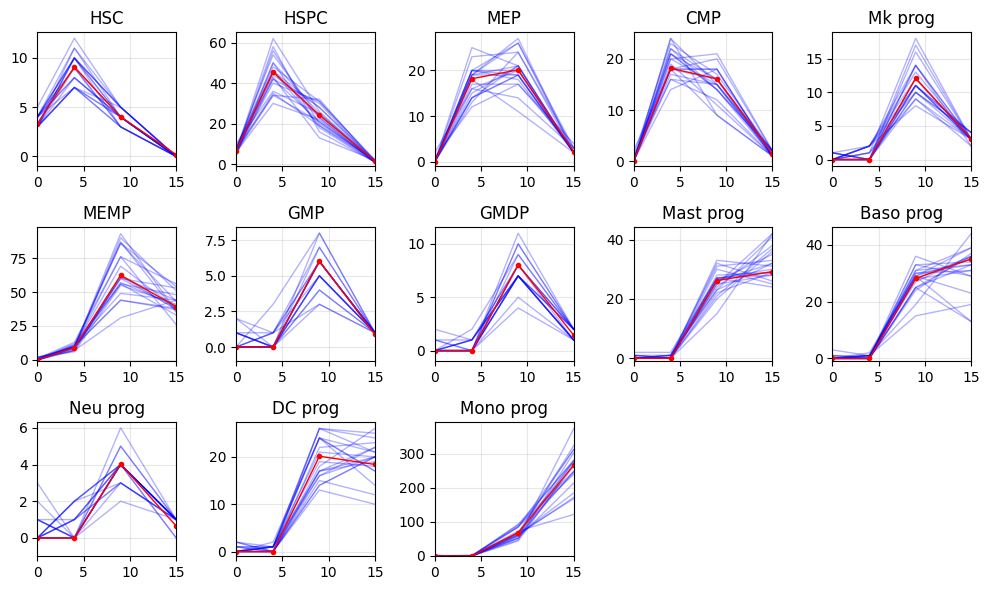


Simulation complete. Data saved to: in_silico/simulated_data/simulated_clones_meta8.csv
Data shape: (20, 52) (20 replicates x 52 features)


In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import os

# ---------------------------------------------------------
# 1. Set Random Seed and Generate Parameters (Meta8 Bias)
# ---------------------------------------------------------

# Set seed for parameter generation
np.random.seed(800) # Changed seed for Meta8

# --- Stem & Early Progenitors ---
p_hsc = 0.2 + np.random.randn() * 0.02
d_hsc = 0.1 + np.random.randn() * 0.01
m_hsc = 0.02 + np.random.randn() * 0.002

p_hspc = 0.3 + np.random.randn() * 0.03
d_hspc = 0.1 + np.random.randn() * 0.01
m_hspc = 0.011 + np.random.randn() * 0.0011

# --- Erythroid / Megakaryocyte Branch ---
p_mep = 0.41 + np.random.randn() * 0.041
d_mep = 0.11 + np.random.randn() * 0.011
m_mep = 0.012 + np.random.randn() * 0.0012

p_cmp = 0.2 + np.random.randn() * 0.02
d_cmp = 0.09 + np.random.randn() * 0.009
m_cmp = 0.02 + np.random.randn() * 0.002

p_mk = 0.29 + np.random.randn() * 0.029
m_mk = 0.02 + np.random.randn() * 0.002

p_memp = 0.6 + np.random.randn() * 0.06
d_memp = 0.1 + np.random.randn() * 0.01
m_memp = 0.015 + np.random.randn() * 0.0015

# --- Granulocyte / Monocyte Branch ---
p_gmp = 0.5 + np.random.randn() * 0.05
d_gmp = 0.3 + np.random.randn() * 0.03
m_gmp = 0.018 + np.random.randn() * 0.0018

# MODIFICATION: Increased GMDP proliferation to feed Mono/DC
p_gmdp = 0.6 + np.random.randn() * 0.04 
d_gmdp = 0.3 + np.random.randn() * 0.03
m_gmdp = 0.071 + np.random.randn() * 0.0071

# --- Terminal Lineages ---
p_mast = 0.6 + np.random.randn() * 0.06
m_mast = 0.08 + np.random.randn() * 0.008

p_baso = 0.51 + np.random.randn() * 0.051
m_baso = 0.02 + np.random.randn() * 0.002

# MODIFICATION: Suppressed Neutrophils to emphasize Mono bias
p_neu = 0.1 + np.random.randn() * 0.03 
m_neu = 0.133 + np.random.randn() * 0.0133

p_dc = 0.6 + np.random.randn() * 0.06
m_dc = 0.11 + np.random.randn() * 0.011

# MODIFICATION: Drastic increase in Monocyte proliferation
p_mono = 0.85 + np.random.randn() * 0.0145 
m_mono = 0.012 + np.random.randn() * 0.0012

print("Generated parameters for Meta8 (Mono Bias):")
print(f"p_mono={p_mono:.4f} (High), p_neu={p_neu:.4f} (Low)")
print(f"p_gmdp={p_gmdp:.4f} (High)")

# ---------------------------------------------------------
# 2. Define ODE System with Generated Parameters
# ---------------------------------------------------------

def hematopoietic_model(t, y):
    dydt = np.zeros_like(y)
    x = y 

    # ODE Equations
    dydt[0] = (p_hsc - d_hsc - m_hsc) * x[0] 
    dydt[1] = (p_hspc - d_hspc - m_hspc) * x[1] + d_hsc * x[0]
    dydt[2] = (p_mep - d_mep - m_mep) * x[2] + d_hspc * x[1]
    dydt[3] = (p_cmp - d_cmp - m_cmp) * x[3] + d_hspc * x[1]
    dydt[4] = (p_mk - m_mk) * x[4] + d_mep * x[2]
    dydt[5] = (p_memp - d_memp - m_memp) * x[5] + d_mep * x[2] + d_cmp * x[3]
    dydt[6] = (p_gmp - d_gmp - m_gmp) * x[6] + d_cmp * x[3]
    dydt[7] = (p_gmdp - d_gmdp - m_gmdp) * x[7] + d_cmp * x[3]
    dydt[8] = (p_mast - m_mast) * x[8] + d_memp * x[5]
    dydt[9] = (p_baso - m_baso) * x[9] + d_memp * x[5]
    dydt[10] = (p_neu - m_neu) * x[10] + d_gmp * x[6]
    dydt[11] = (p_dc - m_dc) * x[11] + d_gmdp * x[7]
    dydt[12] = (p_mono - m_mono) * x[12] + d_gmdp * x[7]

    return dydt

# ---------------------------------------------------------
# 3. Simulation Setup
# ---------------------------------------------------------

cell_types = ['HSC', 'HSPC', 'MEP', 'CMP', 'Mk prog', 'MEMP', 
              'GMP', 'GMDP', 'Mast prog', 'Baso prog', 'Neu prog', 
              'DC prog', 'Mono prog']

time_points = np.array([0, 4, 9, 15])
t_plot = np.linspace(0, 20, 2001)

# Initial Conditions: HSC=1, HSPC=2, others=0
I0 = np.zeros(13)
I0[0] = 1.0  # HSC
I0[1] = 2.0  # HSPC

# ---------------------------------------------------------
# 4. Solve ODEs (Deterministic)
# ---------------------------------------------------------

sol_plot = solve_ivp(hematopoietic_model, [0, 20], I0, t_eval=t_plot, method='RK45')
sol_sample = solve_ivp(hematopoietic_model, [0, 15], I0, t_eval=time_points, method='RK45')

# Determine model values at sampling points (Time x Cell)
model_deterministic = np.round(sol_sample.y.T)

# --- SCALING SECTION ---
# Calculate current sum across cells for each timepoint
current_sums = model_deterministic.sum(axis=1, keepdims=True)

# Target sums for each timepoint: [10, 100, 300, 400]
target_sums = np.array([10, 100, 300, 400]).reshape(-1, 1)

# Normalize and Scale: (Model / Current_Sum) * Target_Sum
model_deterministic = (model_deterministic / current_sums) * target_sums
# ----------------------

# Calculate deviation
dev = model_deterministic * 0.2
dev[dev == 0] = 1 

# ---------------------------------------------------------
# 5. Generate Noise Replicates
# ---------------------------------------------------------

num_replicates = 20
model_noise_store = np.zeros((num_replicates, len(time_points) * 13))
all_noisy_trajectories = [] 

for nn in range(1, num_replicates + 1):
    np.random.seed(nn)
    
    noise = np.random.randn(*model_deterministic.shape) * dev
    model_noise = model_deterministic + noise
    
    model_noise = np.round(model_noise)
    model_noise[model_noise < 0] = 0
    
    # Store flattened (row-major)
    model_noise_store[nn-1, :] = model_noise.flatten() 
    all_noisy_trajectories.append(model_noise)

# ---------------------------------------------------------
# 6. Plotting
# ---------------------------------------------------------

fig, axes = plt.subplots(3, 5, figsize=(10, 6))
axes = axes.flatten()

for j in range(13):
    ax = axes[j]
    
    # Plot noisy replicates
    for noisy_data in all_noisy_trajectories:
        ax.plot(time_points, noisy_data[:, j], '-b', alpha=0.3, linewidth=1)
    
    # Plot mean of scaled deterministic model
    ax.plot(time_points, model_deterministic[:, j], '-ro', linewidth=1, 
            markersize=3, label='Scaled model' if j==0 else "")

    ax.set_title(cell_types[j])
    ax.set_ylim(bottom=-1)
    ax.set_xlim([0, 15])
    ax.grid(True, alpha=0.3)

axes[13].axis('off')
axes[14].axis('off')

if axes[0].get_legend():
    axes[0].legend()

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 7. Saving Data
# ---------------------------------------------------------

output_folder = "in_silico/simulated_data/"
filename = "simulated_clones_meta8.csv"
file_path = os.path.join(output_folder, filename)

if not os.path.exists(output_folder):
    os.makedirs(output_folder)

# COMMENT: Saving the meta8 scaled simulated noise data with Mono bias to CSV
np.savetxt(file_path, model_noise_store, delimiter=",", fmt='%.4f')

print(f"\nSimulation complete. Data saved to: {file_path}")
print(f"Data shape: {model_noise_store.shape} ({num_replicates} replicates x {len(time_points)*13} features)")

# 9. Cell Dying Out / Catastrophic Collapse Scenario (Meta9)

**Metaclone Type**: Dying clone scenario with lineage bias.
- **Initial Conditions**: HSC = 1.0, HSPC = 2.0.
- **Target Sums**: Collapse to near-zero at day 9 and absolute zero at day 15 (`target_sums = [10, 100, 20, 0]`), simulating a terminal catastrophic cell death event starting at `t = 7.5`.
- **Parameters**: Generated stochastically using random seed `900`. Retains the Meta8 Monocyte lineage bias parameters.
- **Replicates**: 37 noise replicates.


Generated parameters for Meta9 (Dying Out):
Standard parameters generated. Kill switch active > t=7.5.


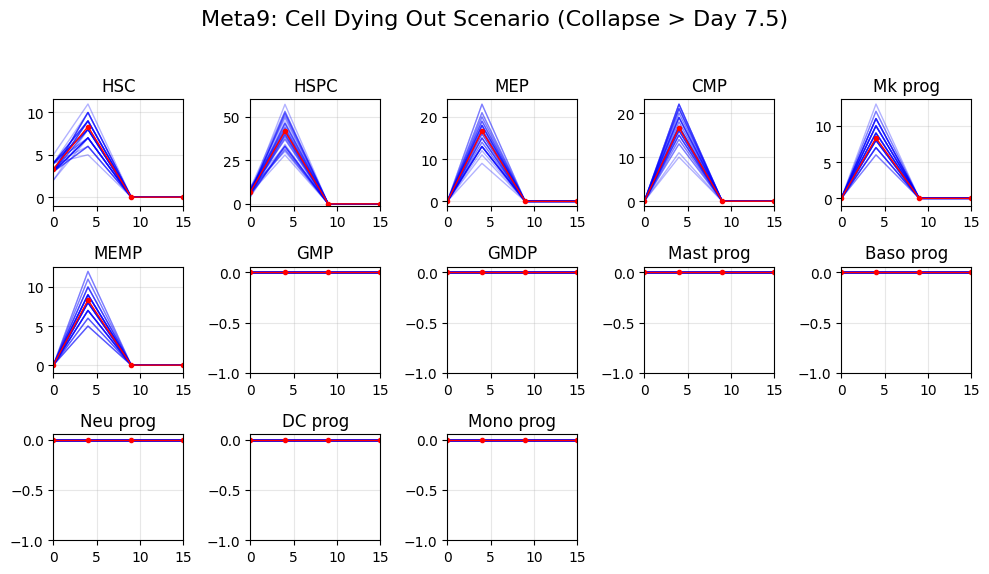


Simulation complete. Data saved to: in_silico/simulated_data/simulated_clones_meta9.csv
Data shape: (37, 52) (37 replicates x 52 features)


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import os

# ---------------------------------------------------------
# 1. Set Random Seed and Generate Parameters (Meta8 Bias kept)
# ---------------------------------------------------------

# Set seed for parameter generation
np.random.seed(900) 

# --- Stem & Early Progenitors ---
p_hsc = 0.2 + np.random.randn() * 0.02
d_hsc = 0.1 + np.random.randn() * 0.01
m_hsc = 0.02 + np.random.randn() * 0.002

p_hspc = 0.3 + np.random.randn() * 0.03
d_hspc = 0.1 + np.random.randn() * 0.01
m_hspc = 0.011 + np.random.randn() * 0.0011

# --- Erythroid / Megakaryocyte Branch ---
p_mep = 0.41 + np.random.randn() * 0.041
d_mep = 0.11 + np.random.randn() * 0.011
m_mep = 0.012 + np.random.randn() * 0.0012

p_cmp = 0.2 + np.random.randn() * 0.02
d_cmp = 0.09 + np.random.randn() * 0.009
m_cmp = 0.02 + np.random.randn() * 0.002

p_mk = 0.29 + np.random.randn() * 0.029
m_mk = 0.02 + np.random.randn() * 0.002

p_memp = 0.6 + np.random.randn() * 0.06
d_memp = 0.1 + np.random.randn() * 0.01
m_memp = 0.015 + np.random.randn() * 0.0015

# --- Granulocyte / Monocyte Branch ---
p_gmp = 0.5 + np.random.randn() * 0.05
d_gmp = 0.3 + np.random.randn() * 0.03
m_gmp = 0.018 + np.random.randn() * 0.0018

# (Kept Meta8 Bias) High GMDP
p_gmdp = 0.6 + np.random.randn() * 0.04 
d_gmdp = 0.3 + np.random.randn() * 0.03
m_gmdp = 0.071 + np.random.randn() * 0.0071

# --- Terminal Lineages ---
p_mast = 0.6 + np.random.randn() * 0.06
m_mast = 0.08 + np.random.randn() * 0.008

p_baso = 0.51 + np.random.randn() * 0.051
m_baso = 0.02 + np.random.randn() * 0.002

# (Kept Meta8 Bias) Suppressed Neu
p_neu = 0.1 + np.random.randn() * 0.03 
m_neu = 0.133 + np.random.randn() * 0.0133

p_dc = 0.6 + np.random.randn() * 0.06
m_dc = 0.11 + np.random.randn() * 0.011

# (Kept Meta8 Bias) High Mono
p_mono = 0.85 + np.random.randn() * 0.0145 
m_mono = 0.012 + np.random.randn() * 0.0012

print("Generated parameters for Meta9 (Dying Out):")
print("Standard parameters generated. Kill switch active > t=7.5.")

# ---------------------------------------------------------
# 2. Define ODE System with Kill Switch
# ---------------------------------------------------------

def hematopoietic_model(t, y):
    dydt = np.zeros_like(y)
    x = y 

    # META9 FEATURE: Catastrophic death event starts at t=7.5
    kill_rate = 0.0
    if t > 7.5:
        kill_rate = 5.0 # Massive death rate added to all cells

    # ODE Equations
    dydt[0] = (p_hsc - d_hsc - m_hsc) * x[0] 
    dydt[1] = (p_hspc - d_hspc - m_hspc) * x[1] + d_hsc * x[0]
    dydt[2] = (p_mep - d_mep - m_mep) * x[2] + d_hspc * x[1]
    dydt[3] = (p_cmp - d_cmp - m_cmp) * x[3] + d_hspc * x[1]
    dydt[4] = (p_mk - m_mk) * x[4] + d_mep * x[2]
    dydt[5] = (p_memp - d_memp - m_memp) * x[5] + d_mep * x[2] + d_cmp * x[3]
    dydt[6] = (p_gmp - d_gmp - m_gmp) * x[6] + d_cmp * x[3]
    dydt[7] = (p_gmdp - d_gmdp - m_gmdp) * x[7] + d_cmp * x[3]
    dydt[8] = (p_mast - m_mast) * x[8] + d_memp * x[5]
    dydt[9] = (p_baso - m_baso) * x[9] + d_memp * x[5]
    dydt[10] = (p_neu - m_neu) * x[10] + d_gmp * x[6]
    dydt[11] = (p_dc - m_dc) * x[11] + d_gmdp * x[7]
    dydt[12] = (p_mono - m_mono) * x[12] + d_gmdp * x[7]

    # Apply kill rate to the entire system dynamics
    dydt -= kill_rate * x

    return dydt

# ---------------------------------------------------------
# 3. Simulation Setup
# ---------------------------------------------------------

cell_types = ['HSC', 'HSPC', 'MEP', 'CMP', 'Mk prog', 'MEMP', 
              'GMP', 'GMDP', 'Mast prog', 'Baso prog', 'Neu prog', 
              'DC prog', 'Mono prog']

time_points = np.array([0, 4, 9, 15])
t_plot = np.linspace(0, 20, 2001)

# Initial Conditions: HSC=1, HSPC=2, others=0
I0 = np.zeros(13)
I0[0] = 1.0  # HSC
I0[1] = 2.0  # HSPC

# ---------------------------------------------------------
# 4. Solve ODEs (Deterministic)
# ---------------------------------------------------------

sol_plot = solve_ivp(hematopoietic_model, [0, 20], I0, t_eval=t_plot, method='RK45')
sol_sample = solve_ivp(hematopoietic_model, [0, 15], I0, t_eval=time_points, method='RK45')

# Determine model values at sampling points (Time x Cell)
model_deterministic = np.round(sol_sample.y.T)
model_deterministic[model_deterministic < 0] = 0 # Safety clip

# --- SCALING SECTION ---
# Calculate current sum across cells for each timepoint
current_sums = model_deterministic.sum(axis=1, keepdims=True)
current_sums[current_sums == 0] = 1.0 # Avoid division by zero for the dead timepoints

# META9 FEATURE: Target sums collapse to near zero at day 9 and zero at day 15
# Previous: [10, 100, 300, 400]
target_sums = np.array([10, 100, 20, 0]).reshape(-1, 1)

# Normalize and Scale: (Model / Current_Sum) * Target_Sum
model_deterministic = (model_deterministic / current_sums) * target_sums
# ----------------------

# Calculate deviation
dev = model_deterministic * 0.2
# If model is 0 (at t=15), dev is 0. Prevent dev=0 for noise generation elsewhere, 
# but here we actually want 0 variance if the count is 0.
# However, to match previous logic, we usually set dev[dev==0]=1. 
# But for "dead" timepoints, we want noise to be 0.
dev[dev == 0] = 0.01 # Small epsilon to prevent issues, or keep 0. 
# If target is 0, model is 0. We should likely keep noise low.

# ---------------------------------------------------------
# 5. Generate Noise Replicates
# ---------------------------------------------------------

num_replicates = 37
model_noise_store = np.zeros((num_replicates, len(time_points) * 13))
all_noisy_trajectories = [] 

for nn in range(1, num_replicates + 1):
    np.random.seed(nn)
    
    noise = np.random.randn(*model_deterministic.shape) * dev
    model_noise = model_deterministic + noise
    
    model_noise = np.round(model_noise)
    model_noise[model_noise < 0] = 0
    
    # Store flattened (row-major)
    model_noise_store[nn-1, :] = model_noise.flatten() 
    all_noisy_trajectories.append(model_noise)

# ---------------------------------------------------------
# 6. Plotting
# ---------------------------------------------------------

fig, axes = plt.subplots(3, 5, figsize=(10, 6))
axes = axes.flatten()

for j in range(13):
    ax = axes[j]
    
    # Plot noisy replicates
    for noisy_data in all_noisy_trajectories:
        ax.plot(time_points, noisy_data[:, j], '-b', alpha=0.3, linewidth=1)
    
    # Plot mean of scaled deterministic model
    ax.plot(time_points, model_deterministic[:, j], '-ro', linewidth=1, 
            markersize=3, label='Scaled model' if j==0 else "")

    ax.set_title(cell_types[j])
    ax.set_ylim(bottom=-1)
    ax.set_xlim([0, 15])
    ax.grid(True, alpha=0.3)

axes[13].axis('off')
axes[14].axis('off')

if axes[0].get_legend():
    axes[0].legend()

plt.suptitle("Meta9: Cell Dying Out Scenario (Collapse > Day 7.5)", fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

# ---------------------------------------------------------
# 7. Saving Data
# ---------------------------------------------------------

output_folder = "in_silico/simulated_data/"
filename = "simulated_clones_meta9.csv"
file_path = os.path.join(output_folder, filename)

if not os.path.exists(output_folder):
    os.makedirs(output_folder)

# COMMENT: Saving the meta9 scaled simulated noise data (dying out) to CSV
np.savetxt(file_path, model_noise_store, delimiter=",", fmt='%.4f')

print(f"\nSimulation complete. Data saved to: {file_path}")
print(f"Data shape: {model_noise_store.shape} ({num_replicates} replicates x {len(time_points)*13} features)")

# 10. Slowed/Delayed Dynamics (Meta10)

**Metaclone Type**: Stretched/slowed dynamics simulation.
- **Initial Conditions**: HSC = 1.0, HSPC = 2.0.
- **Target Sums**: Rescaled to standard population sizes of `[10, 100, 300, 400]`.
- **Parameters**: Generated stochastically using random seed `900`, with all proliferation and differentiation rates scaled by `slow_factor = 0.25` (4x slower). Migration and death rates are scaled less aggressively to prevent washouts.
- **Replicates**: 53 noise replicates.


Generated parameters for Meta10 (Slowed/Delayed):
p_hsc=0.0411 (approx 0.25x of original)
d_hsc=0.0234 (approx 0.25x of original)


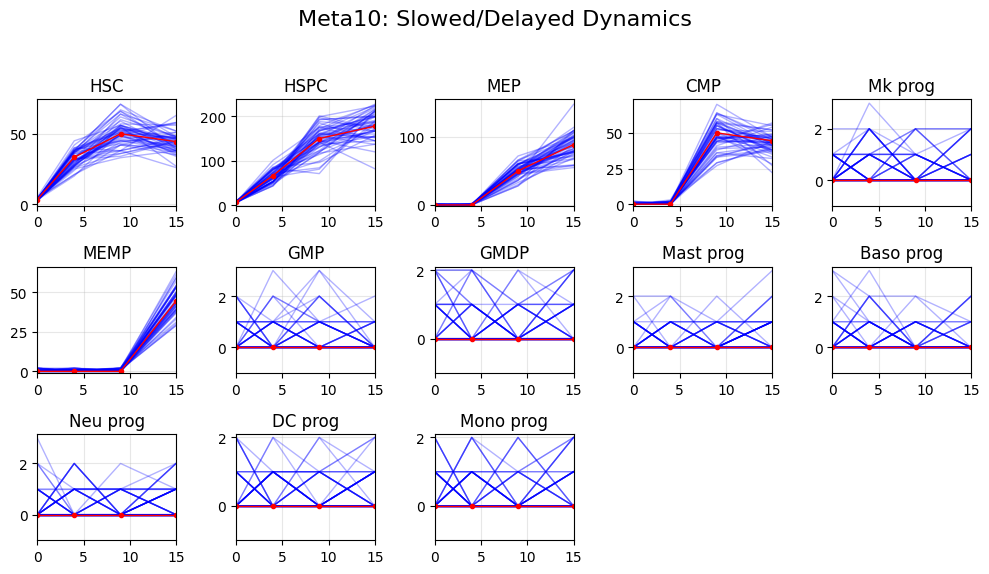


Simulation complete. Data saved to: in_silico/simulated_data/simulated_clones_meta10.csv
Data shape: (53, 52) (53 replicates x 52 features)


In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import os

# ---------------------------------------------------------
# 1. Set Random Seed and Generate Parameters (Meta10 Slowed)
# ---------------------------------------------------------

# Set seed for parameter generation
np.random.seed(900) # New seed for Meta10

# Scaling factor to slow down dynamics (approx 4x slower)
# This effectively delays the "biological time" relative to "clock time"
slow_factor = 0.25

# Generate parameters with random noise, scaled by slow_factor
# Note: Migration/Death (m) is scaled less aggressively to avoid total washout
p_hsc = (0.2 + np.random.randn() * 0.02) * slow_factor
d_hsc = (0.1 + np.random.randn() * 0.01) * slow_factor
m_hsc = 0.02 + np.random.randn() * 0.002

p_hspc = (0.3 + np.random.randn() * 0.03) * slow_factor
d_hspc = (0.1 + np.random.randn() * 0.01) * slow_factor
m_hspc = 0.011 + np.random.randn() * 0.0011

p_mep = (0.41 + np.random.randn() * 0.041) * slow_factor
d_mep = (0.11 + np.random.randn() * 0.011) * slow_factor
m_mep = 0.012 + np.random.randn() * 0.0012

p_cmp = (0.2 + np.random.randn() * 0.02) * slow_factor
d_cmp = (0.09 + np.random.randn() * 0.009) * slow_factor
m_cmp = 0.02 + np.random.randn() * 0.002

p_mk = (0.29 + np.random.randn() * 0.029) * slow_factor
m_mk = 0.02 + np.random.randn() * 0.002

p_memp = (0.6 + np.random.randn() * 0.06) * slow_factor
d_memp = (0.1 + np.random.randn() * 0.01) * slow_factor
m_memp = 0.015 + np.random.randn() * 0.0015

p_gmp = (0.5 + np.random.randn() * 0.05) * slow_factor
d_gmp = (0.3 + np.random.randn() * 0.03) * slow_factor
m_gmp = 0.018 + np.random.randn() * 0.0018

p_gmdp = (0.4 + np.random.randn() * 0.04) * slow_factor
d_gmdp = (0.3 + np.random.randn() * 0.03) * slow_factor
m_gmdp = 0.071 + np.random.randn() * 0.0071

p_mast = (0.6 + np.random.randn() * 0.06) * slow_factor
m_mast = 0.08 + np.random.randn() * 0.008

p_baso = (0.51 + np.random.randn() * 0.051) * slow_factor
m_baso = 0.02 + np.random.randn() * 0.002

p_neu = (0.3 + np.random.randn() * 0.03) * slow_factor
m_neu = 0.133 + np.random.randn() * 0.0133

p_dc = (0.6 + np.random.randn() * 0.06) * slow_factor
m_dc = 0.11 + np.random.randn() * 0.011

p_mono = (0.145 + np.random.randn() * 0.0145) * slow_factor
m_mono = 0.012 + np.random.randn() * 0.0012

print("Generated parameters for Meta10 (Slowed/Delayed):")
print(f"p_hsc={p_hsc:.4f} (approx {slow_factor}x of original)")
print(f"d_hsc={d_hsc:.4f} (approx {slow_factor}x of original)")

# ---------------------------------------------------------
# 2. Define ODE System
# ---------------------------------------------------------

def hematopoietic_model(t, y):
    dydt = np.zeros_like(y)
    x = y 

    # ODE Equations (using globally generated parameters)
    dydt[0] = (p_hsc - d_hsc - m_hsc) * x[0] 
    dydt[1] = (p_hspc - d_hspc - m_hspc) * x[1] + d_hsc * x[0]
    dydt[2] = (p_mep - d_mep - m_mep) * x[2] + d_hspc * x[1]
    dydt[3] = (p_cmp - d_cmp - m_cmp) * x[3] + d_hspc * x[1]
    dydt[4] = (p_mk - m_mk) * x[4] + d_mep * x[2]
    dydt[5] = (p_memp - d_memp - m_memp) * x[5] + d_mep * x[2] + d_cmp * x[3]
    dydt[6] = (p_gmp - d_gmp - m_gmp) * x[6] + d_cmp * x[3]
    dydt[7] = (p_gmdp - d_gmdp - m_gmdp) * x[7] + d_cmp * x[3]
    dydt[8] = (p_mast - m_mast) * x[8] + d_memp * x[5]
    dydt[9] = (p_baso - m_baso) * x[9] + d_memp * x[5]
    dydt[10] = (p_neu - m_neu) * x[10] + d_gmp * x[6]
    dydt[11] = (p_dc - m_dc) * x[11] + d_gmdp * x[7]
    dydt[12] = (p_mono - m_mono) * x[12] + d_gmdp * x[7]

    return dydt

# ---------------------------------------------------------
# 3. Simulation Setup
# ---------------------------------------------------------

cell_types = ['HSC', 'HSPC', 'MEP', 'CMP', 'Mk prog', 'MEMP', 
              'GMP', 'GMDP', 'Mast prog', 'Baso prog', 'Neu prog', 
              'DC prog', 'Mono prog']

time_points = np.array([0, 4, 9, 15])
t_plot = np.linspace(0, 20, 2001)

# Initial Conditions: HSC=1, HSPC=2, others=0
I0 = np.zeros(13)
I0[0] = 1.0  # HSC
I0[1] = 2.0  # HSPC

# ---------------------------------------------------------
# 4. Solve ODEs (Deterministic)
# ---------------------------------------------------------

sol_plot = solve_ivp(hematopoietic_model, [0, 20], I0, t_eval=t_plot, method='RK45')
sol_sample = solve_ivp(hematopoietic_model, [0, 15], I0, t_eval=time_points, method='RK45')

# Determine model values at sampling points (Time x Cell)
model_deterministic = np.round(sol_sample.y.T)

# --- SCALING SECTION ---
# Calculate current sum across cells for each timepoint
current_sums = model_deterministic.sum(axis=1, keepdims=True)

# Target sums: Same as original [10, 100, 300, 400]
# Note: Because dynamics are slower, the model might struggle to reach high counts
# naturally, but this scaling forces the "observed" total count to match the original pattern.
# The *proportions* will be "delayed" (less mature cells at later timepoints).
target_sums = np.array([10, 100, 300, 400]).reshape(-1, 1)

# Normalize and Scale
model_deterministic = (model_deterministic / current_sums) * target_sums
# ----------------------

# Calculate deviation
dev = model_deterministic * 0.2
dev[dev == 0] = 1 

# ---------------------------------------------------------
# 5. Generate Noise Replicates
# ---------------------------------------------------------

num_replicates = 53
model_noise_store = np.zeros((num_replicates, len(time_points) * 13))
all_noisy_trajectories = [] 

for nn in range(1, num_replicates + 1):
    np.random.seed(nn)
    
    noise = np.random.randn(*model_deterministic.shape) * dev
    model_noise = model_deterministic + noise
    
    model_noise = np.round(model_noise)
    model_noise[model_noise < 0] = 0
    
    # Store flattened (row-major)
    model_noise_store[nn-1, :] = model_noise.flatten() 
    all_noisy_trajectories.append(model_noise)

# ---------------------------------------------------------
# 6. Plotting
# ---------------------------------------------------------

fig, axes = plt.subplots(3, 5, figsize=(10, 6))
axes = axes.flatten()

for j in range(13):
    ax = axes[j]
    
    # Plot noisy replicates
    for noisy_data in all_noisy_trajectories:
        ax.plot(time_points, noisy_data[:, j], '-b', alpha=0.3, linewidth=1)
    
    # Plot mean of scaled deterministic model
    ax.plot(time_points, model_deterministic[:, j], '-ro', linewidth=1, 
            markersize=3, label='Scaled model' if j==0 else "")

    ax.set_title(cell_types[j])
    ax.set_ylim(bottom=-1)
    ax.set_xlim([0, 15]) 
    ax.grid(True, alpha=0.3)

axes[13].axis('off')
axes[14].axis('off')

if axes[0].get_legend():
    axes[0].legend()

plt.suptitle("Meta10: Slowed/Delayed Dynamics", fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

# ---------------------------------------------------------
# 7. Saving Data
# ---------------------------------------------------------

output_folder = "in_silico/simulated_data/"
filename = "simulated_clones_meta10.csv"
file_path = os.path.join(output_folder, filename)

if not os.path.exists(output_folder):
    os.makedirs(output_folder)

# COMMENT: Saving the meta10 scaled simulated noise data (slowed) to CSV
np.savetxt(file_path, model_noise_store, delimiter=",", fmt='%.4f')

print(f"\nSimulation complete. Data saved to: {file_path}")
print(f"Data shape: {model_noise_store.shape} ({num_replicates} replicates x {len(time_points)*13} features)")

# 11. Biological Stalling - Extreme Differentiation Block (Meta11)

**Metaclone Type**: Early progenitor differentiation blockade.
- **Initial Conditions**: HSC = 1.0, HSPC = 2.0.
- **Target Sums**: Rescaled to standard population sizes of `[10, 100, 300, 400]`.
- **Parameters**: Generated stochastically using random seed `1100`. Features an extreme differentiation block at the HSC/HSPC stage where differentiation rates are reduced to near zero (`d_hsc = 0.001`, `d_hspc = 0.001`), leading to HSC/HSPC accumulation and downstream stagnation.
- **Replicates**: 26 noise replicates.


Generated parameters for Meta12 (Biological Stalling):
d_hsc=0.00087 (Extremely Low)
d_hspc=0.00105 (Extremely Low)


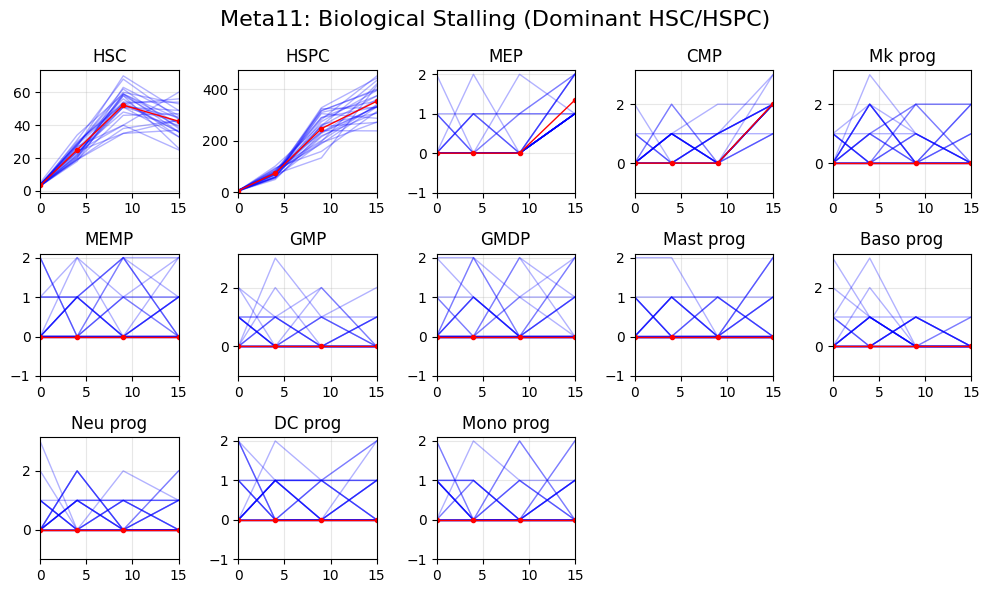


Simulation complete. Data saved to: in_silico/simulated_data/simulated_clones_meta11.csv
Data shape: (26, 52) (26 replicates x 52 features)


In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import os

# ---------------------------------------------------------
# 1. Set Random Seed and Generate Parameters (Meta11)
# ---------------------------------------------------------

# Set seed
np.random.seed(1100)

# --- META12 MODIFICATION: EXTREME DIFFERENTIATION BLOCK ---
# We reduce 'd' (differentiation) rates to near zero.
# This causes cells to accumulate in HSC/HSPC and not flow downstream.

# HSC: Normal proliferation, but tiny differentiation
p_hsc = 0.3 + np.random.randn() * 0.02
d_hsc = 0.001 + np.random.randn() * 0.0001  # <--- The bottleneck
m_hsc = 0.02 + np.random.randn() * 0.002

# HSPC: Normal proliferation, tiny differentiation
p_hspc = 0.4 + np.random.randn() * 0.03
d_hspc = 0.001 + np.random.randn() * 0.0001 # <--- The bottleneck
m_hspc = 0.011 + np.random.randn() * 0.0011

# --- Downstream Progenitors (Parameters exist but get little input) ---
# We also slow these down to fit the "slow system" theme
p_mep = 0.2 + np.random.randn() * 0.02
d_mep = 0.01 + np.random.randn() * 0.001
m_mep = 0.012 + np.random.randn() * 0.0012

p_cmp = 0.2 + np.random.randn() * 0.02
d_cmp = 0.01 + np.random.randn() * 0.001
m_cmp = 0.02 + np.random.randn() * 0.002

p_mk = 0.2 + np.random.randn() * 0.02
m_mk = 0.02 + np.random.randn() * 0.002

p_memp = 0.2 + np.random.randn() * 0.02
d_memp = 0.01 + np.random.randn() * 0.001
m_memp = 0.015 + np.random.randn() * 0.0015

p_gmp = 0.2 + np.random.randn() * 0.02
d_gmp = 0.01 + np.random.randn() * 0.001
m_gmp = 0.018 + np.random.randn() * 0.0018

p_gmdp = 0.2 + np.random.randn() * 0.02
d_gmdp = 0.01 + np.random.randn() * 0.001
m_gmdp = 0.071 + np.random.randn() * 0.0071

p_mast = 0.2 + np.random.randn() * 0.02
m_mast = 0.08 + np.random.randn() * 0.008

p_baso = 0.2 + np.random.randn() * 0.02
m_baso = 0.02 + np.random.randn() * 0.002

p_neu = 0.2 + np.random.randn() * 0.02
m_neu = 0.133 + np.random.randn() * 0.0133

p_dc = 0.2 + np.random.randn() * 0.02
m_dc = 0.11 + np.random.randn() * 0.011

p_mono = 0.2 + np.random.randn() * 0.0145
m_mono = 0.012 + np.random.randn() * 0.0012

print("Generated parameters for Meta12 (Biological Stalling):")
print(f"d_hsc={d_hsc:.5f} (Extremely Low)")
print(f"d_hspc={d_hspc:.5f} (Extremely Low)")

# ---------------------------------------------------------
# 2. Define ODE System
# ---------------------------------------------------------

def hematopoietic_model(t, y):
    dydt = np.zeros_like(y)
    x = y 

    # ODE Equations
    dydt[0] = (p_hsc - d_hsc - m_hsc) * x[0] 
    dydt[1] = (p_hspc - d_hspc - m_hspc) * x[1] + d_hsc * x[0]
    dydt[2] = (p_mep - d_mep - m_mep) * x[2] + d_hspc * x[1]
    dydt[3] = (p_cmp - d_cmp - m_cmp) * x[3] + d_hspc * x[1]
    dydt[4] = (p_mk - m_mk) * x[4] + d_mep * x[2]
    dydt[5] = (p_memp - d_memp - m_memp) * x[5] + d_mep * x[2] + d_cmp * x[3]
    dydt[6] = (p_gmp - d_gmp - m_gmp) * x[6] + d_cmp * x[3]
    dydt[7] = (p_gmdp - d_gmdp - m_gmdp) * x[7] + d_cmp * x[3]
    dydt[8] = (p_mast - m_mast) * x[8] + d_memp * x[5]
    dydt[9] = (p_baso - m_baso) * x[9] + d_memp * x[5]
    dydt[10] = (p_neu - m_neu) * x[10] + d_gmp * x[6]
    dydt[11] = (p_dc - m_dc) * x[11] + d_gmdp * x[7]
    dydt[12] = (p_mono - m_mono) * x[12] + d_gmdp * x[7]

    return dydt

# ---------------------------------------------------------
# 3. Simulation Setup
# ---------------------------------------------------------

cell_types = ['HSC', 'HSPC', 'MEP', 'CMP', 'Mk prog', 'MEMP', 
              'GMP', 'GMDP', 'Mast prog', 'Baso prog', 'Neu prog', 
              'DC prog', 'Mono prog']

time_points = np.array([0, 4, 9, 15])
t_plot = np.linspace(0, 20, 2001)

# Initial Conditions: HSC=1, HSPC=2, others=0
I0 = np.zeros(13)
I0[0] = 1.0  # HSC
I0[1] = 2.0  # HSPC

# ---------------------------------------------------------
# 4. Solve ODEs (Deterministic)
# ---------------------------------------------------------

sol_plot = solve_ivp(hematopoietic_model, [0, 20], I0, t_eval=t_plot, method='RK45')
sol_sample = solve_ivp(hematopoietic_model, [0, 15], I0, t_eval=time_points, method='RK45')

# Determine model values at sampling points (Time x Cell)
model_deterministic = np.round(sol_sample.y.T)

# --- SCALING SECTION ---
# Calculate current sum across cells for each timepoint
current_sums = model_deterministic.sum(axis=1, keepdims=True)

# Target sums for each timepoint: [10, 100, 300, 400]
target_sums = np.array([10, 100, 300, 400]).reshape(-1, 1)

# Normalize and Scale: (Model / Current_Sum) * Target_Sum
model_deterministic = (model_deterministic / current_sums) * target_sums
# ----------------------

# Calculate deviation
dev = model_deterministic * 0.2
dev[dev == 0] = 1 

# ---------------------------------------------------------
# 5. Generate Noise Replicates
# ---------------------------------------------------------

num_replicates = 26
model_noise_store = np.zeros((num_replicates, len(time_points) * 13))
all_noisy_trajectories = [] 

for nn in range(1, num_replicates + 1):
    np.random.seed(nn)
    
    noise = np.random.randn(*model_deterministic.shape) * dev
    model_noise = model_deterministic + noise
    
    model_noise = np.round(model_noise)
    model_noise[model_noise < 0] = 0
    
    # Store flattened (row-major)
    model_noise_store[nn-1, :] = model_noise.flatten() 
    all_noisy_trajectories.append(model_noise)

# ---------------------------------------------------------
# 6. Plotting
# ---------------------------------------------------------

fig, axes = plt.subplots(3, 5, figsize=(10, 6))
axes = axes.flatten()

for j in range(13):
    ax = axes[j]
    
    # Plot noisy replicates
    for noisy_data in all_noisy_trajectories:
        ax.plot(time_points, noisy_data[:, j], '-b', alpha=0.3, linewidth=1)
    
    # Plot mean of scaled deterministic model at sample points
    ax.plot(time_points, model_deterministic[:, j], '-ro', linewidth=1, 
            markersize=3, label='Scaled model' if j==0 else "")

    ax.set_title(cell_types[j])
    ax.set_ylim(bottom=-1)
    ax.set_xlim([0, 15])
    ax.grid(True, alpha=0.3)

axes[13].axis('off')
axes[14].axis('off')

if axes[0].get_legend():
    axes[0].legend()

plt.suptitle("Meta11: Biological Stalling (Dominant HSC/HSPC)", fontsize=16)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 7. Saving Data
# ---------------------------------------------------------

output_folder = "in_silico/simulated_data/"
filename = "simulated_clones_meta11.csv"
file_path = os.path.join(output_folder, filename)

if not os.path.exists(output_folder):
    os.makedirs(output_folder)

# COMMENT: Saving the meta12 scaled simulated noise data to CSV
np.savetxt(file_path, model_noise_store, delimiter=",", fmt='%.4f')

print(f"\nSimulation complete. Data saved to: {file_path}")
print(f"Data shape: {model_noise_store.shape} ({num_replicates} replicates x {len(time_points)*13} features)")

# 12. HSC Locked - Absolute Differentiation Block (Meta12)

**Metaclone Type**: Absolute differentiation block ("HSC Lock").
- **Initial Conditions**: HSC = 1.0, HSPC = 0.0 (strict starting point).
- **Target Sums**: Rescaled to standard population sizes of `[10, 100, 300, 400]`.
- **Parameters**: Generated stochastically using random seed `1200`. Features an absolute block in flow downstream, with HSC differentiation set to virtually zero (`d_hsc = 0.0001`) and HSPC differentiation set to absolute zero (`d_hspc = 0.0`), locking cells in the HSC stage.
- **Replicates**: 30 noise replicates.


Generated parameters for Meta13 (HSC Only):
d_hsc=0.0001 (Trace), d_hspc=0.0 (Zero)


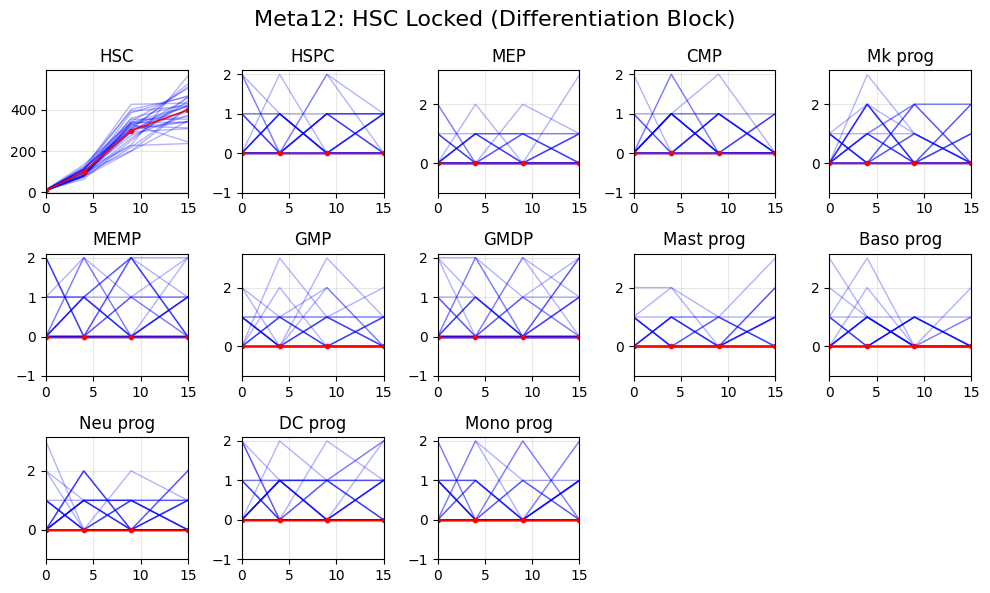


Simulation complete. Data saved to: in_silico/simulated_data/simulated_clones_meta12.csv
Data shape: (30, 52) (30 replicates x 52 features)


In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import os

# ---------------------------------------------------------
# 1. Set Random Seed and Generate Parameters (Meta12)
# ---------------------------------------------------------

# Set seed
np.random.seed(1200)

# --- META13: THE "HSC LOCK" ---
# Proliferation exists, but differentiation is effectively zero.

p_hsc = 0.3 + np.random.randn() * 0.02
d_hsc = 0.0001  # <--- Virtually zero differentiation flux
m_hsc = 0.01 + np.random.randn() * 0.002

p_hspc = 0.3 + np.random.randn() * 0.03
d_hspc = 0.0    # <--- Absolute zero flow downstream
m_hspc = 0.011 + np.random.randn() * 0.0011

# --- Downstream (Irrelevant as no cells reach here) ---
p_mep = 0.41 + np.random.randn() * 0.041
d_mep = 0.11 + np.random.randn() * 0.011
m_mep = 0.012 + np.random.randn() * 0.0012

p_cmp = 0.2 + np.random.randn() * 0.02
d_cmp = 0.09 + np.random.randn() * 0.009
m_cmp = 0.02 + np.random.randn() * 0.002

p_mk = 0.29 + np.random.randn() * 0.029
m_mk = 0.02 + np.random.randn() * 0.002

p_memp = 0.6 + np.random.randn() * 0.06
d_memp = 0.1 + np.random.randn() * 0.01
m_memp = 0.015 + np.random.randn() * 0.0015

p_gmp = 0.5 + np.random.randn() * 0.05
d_gmp = 0.3 + np.random.randn() * 0.03
m_gmp = 0.018 + np.random.randn() * 0.0018

p_gmdp = 0.4 + np.random.randn() * 0.04
d_gmdp = 0.3 + np.random.randn() * 0.03
m_gmdp = 0.071 + np.random.randn() * 0.0071

p_mast = 0.6 + np.random.randn() * 0.06
m_mast = 0.08 + np.random.randn() * 0.008

p_baso = 0.51 + np.random.randn() * 0.051
m_baso = 0.02 + np.random.randn() * 0.002

p_neu = 0.3 + np.random.randn() * 0.03
m_neu = 0.133 + np.random.randn() * 0.0133

p_dc = 0.6 + np.random.randn() * 0.06
m_dc = 0.11 + np.random.randn() * 0.011

p_mono = 0.145 + np.random.randn() * 0.0145
m_mono = 0.012 + np.random.randn() * 0.0012

print("Generated parameters for Meta13 (HSC Only):")
print(f"d_hsc={d_hsc} (Trace), d_hspc={d_hspc} (Zero)")

# ---------------------------------------------------------
# 2. Define ODE System
# ---------------------------------------------------------

def hematopoietic_model(t, y):
    dydt = np.zeros_like(y)
    x = y 

    # ODE Equations
    dydt[0] = (p_hsc - d_hsc - m_hsc) * x[0] 
    dydt[1] = (p_hspc - d_hspc - m_hspc) * x[1] + d_hsc * x[0]
    dydt[2] = (p_mep - d_mep - m_mep) * x[2] + d_hspc * x[1]
    dydt[3] = (p_cmp - d_cmp - m_cmp) * x[3] + d_hspc * x[1]
    dydt[4] = (p_mk - m_mk) * x[4] + d_mep * x[2]
    dydt[5] = (p_memp - d_memp - m_memp) * x[5] + d_mep * x[2] + d_cmp * x[3]
    dydt[6] = (p_gmp - d_gmp - m_gmp) * x[6] + d_cmp * x[3]
    dydt[7] = (p_gmdp - d_gmdp - m_gmdp) * x[7] + d_cmp * x[3]
    dydt[8] = (p_mast - m_mast) * x[8] + d_memp * x[5]
    dydt[9] = (p_baso - m_baso) * x[9] + d_memp * x[5]
    dydt[10] = (p_neu - m_neu) * x[10] + d_gmp * x[6]
    dydt[11] = (p_dc - m_dc) * x[11] + d_gmdp * x[7]
    dydt[12] = (p_mono - m_mono) * x[12] + d_gmdp * x[7]

    return dydt

# ---------------------------------------------------------
# 3. Simulation Setup
# ---------------------------------------------------------

cell_types = ['HSC', 'HSPC', 'MEP', 'CMP', 'Mk prog', 'MEMP', 
              'GMP', 'GMDP', 'Mast prog', 'Baso prog', 'Neu prog', 
              'DC prog', 'Mono prog']

time_points = np.array([0, 4, 9, 15])
t_plot = np.linspace(0, 20, 2001)

# Initial Conditions: HSC=1, HSPC=0 (Strict start)
I0 = np.zeros(13)
I0[0] = 1.0  # HSC
I0[1] = 0.0  # HSPC starts at 0 to ensure only d_hsc flux creates them

# ---------------------------------------------------------
# 4. Solve ODEs (Deterministic)
# ---------------------------------------------------------

sol_plot = solve_ivp(hematopoietic_model, [0, 20], I0, t_eval=t_plot, method='RK45')
sol_sample = solve_ivp(hematopoietic_model, [0, 15], I0, t_eval=time_points, method='RK45')

# Determine model values at sampling points (Time x Cell)
model_deterministic = np.round(sol_sample.y.T)

# --- SCALING SECTION ---
# Calculate current sum across cells for each timepoint
current_sums = model_deterministic.sum(axis=1, keepdims=True)

# Target sums for each timepoint: [10, 100, 300, 400]
target_sums = np.array([10, 100, 300, 400]).reshape(-1, 1)

# Normalize and Scale: (Model / Current_Sum) * Target_Sum
# Note: Since essentially only HSCs exist, HSC count will ~= Target Sum
model_deterministic = (model_deterministic / current_sums) * target_sums
# ----------------------

# Calculate deviation
dev = model_deterministic * 0.2
dev[dev == 0] = 1 

# ---------------------------------------------------------
# 5. Generate Noise Replicates
# ---------------------------------------------------------

num_replicates = 30
model_noise_store = np.zeros((num_replicates, len(time_points) * 13))
all_noisy_trajectories = [] 

for nn in range(1, num_replicates + 1):
    np.random.seed(nn)
    
    noise = np.random.randn(*model_deterministic.shape) * dev
    model_noise = model_deterministic + noise
    
    model_noise = np.round(model_noise)
    model_noise[model_noise < 0] = 0
    
    # Store flattened (row-major)
    model_noise_store[nn-1, :] = model_noise.flatten() 
    all_noisy_trajectories.append(model_noise)

# ---------------------------------------------------------
# 6. Plotting
# ---------------------------------------------------------

fig, axes = plt.subplots(3, 5, figsize=(10, 6))
axes = axes.flatten()

for j in range(13):
    ax = axes[j]
    
    # Plot noisy replicates
    for noisy_data in all_noisy_trajectories:
        ax.plot(time_points, noisy_data[:, j], '-b', alpha=0.3, linewidth=1)
    
    # Plot mean of scaled deterministic model at sample points
    ax.plot(time_points, model_deterministic[:, j], '-ro', linewidth=1, 
            markersize=3, label='Scaled model' if j==0 else "")

    ax.set_title(cell_types[j])
    ax.set_ylim(bottom=-1)
    ax.set_xlim([0, 15])
    ax.grid(True, alpha=0.3)

axes[13].axis('off')
axes[14].axis('off')

if axes[0].get_legend():
    axes[0].legend()

plt.suptitle("Meta12: HSC Locked (Differentiation Block)", fontsize=16)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 7. Saving Data
# ---------------------------------------------------------

output_folder = "in_silico/simulated_data/"
filename = "simulated_clones_meta12.csv"
file_path = os.path.join(output_folder, filename)

if not os.path.exists(output_folder):
    os.makedirs(output_folder)

# COMMENT: Saving the meta13 scaled simulated noise data to CSV
np.savetxt(file_path, model_noise_store, delimiter=",", fmt='%.4f')

print(f"\nSimulation complete. Data saved to: {file_path}")
print(f"Data shape: {model_noise_store.shape} ({num_replicates} replicates x {len(time_points)*13} features)")